<h1><b><center>Astrofísica Galáctica y Extragaláctica</center></b></h1>
<h2><b><center>Prof. Juan Carlos Muñoz</center></b></h1>
<h2><b><center>Primer Parcial - Parte Práctica</center></b><h2>

<h7><center>Juan Fernando Salgado</center><h7>

In [287]:
!pip install plotly


   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.7 MB 8.4 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.7 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 16.3 MB/s  0:00:00

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 

In [150]:
#Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval, ImageNormalize, AsinhStretch, PercentileInterval

from photutils.isophote import Ellipse, EllipseGeometry
from photutils.centroids import centroid_com
from matplotlib.patches import Ellipse as MplEllipse

from scipy.ndimage import gaussian_filter

### Carga e inspección inicial de la imagen de NGC 2403

El análisis se realiza sobre una imagen de **NGC 2403 observada en la banda $g$ del sistema SDSS**, almacenada en formato FITS.

Un archivo FITS contiene principalmente dos elementos relevantes para este análisis:

- una matriz bidimensional con el valor registrado en cada píxel de la imagen;
- una cabecera (*header*) que almacena información asociada a la observación y a su sistema de coordenadas.

A partir de la cabecera se construye además el sistema WCS (*World Coordinate System*), que permitirá posteriormente transformar posiciones medidas sobre la imagen,

$$
(x,y),
$$

expresadas en píxeles, a coordenadas celestes,

$$
(\alpha,\delta),
$$

correspondientes a ascensión recta y declinación.

Antes de realizar cualquier medición fotométrica es conveniente inspeccionar las propiedades básicas de la matriz. Por esta razón se verifican sus dimensiones, el tipo de dato y algunos valores representativos de la distribución de intensidades.


In [3]:
# Ruta de la imagen FITS
ruta_fits = "datos/NGC2403_SDSS_g.fits"

# Abrir el archivo
hdul = fits.open(ruta_fits)

# Datos de imagen
imagen = hdul[0].data

# Cabecera
header = hdul[0].header

# Información WCS
wcs = WCS(header)

print("Dimensiones de la imagen:", imagen.shape)
print("Tipo de datos:", imagen.dtype)

Dimensiones de la imagen: (4096, 4096)
Tipo de datos: >f4


En particular, se calculan el mínimo, el máximo y la mediana. El valor máximo permite reconocer el rango dinámico presente en la observación, mientras que la mediana proporciona una primera referencia del nivel típico de la imagen y es menos sensible que la media a la presencia de fuentes muy brillantes.

In [4]:
print("Valor mínimo:", np.nanmin(imagen))
print("Valor máximo:", np.nanmax(imagen))
print("Valor mediano:", np.nanmedian(imagen))

Valor mínimo: -0.045497004
Valor máximo: 49.890625
Valor mediano: 0.006922693


### Visualización de la imagen y ajuste del contraste

Las imágenes astronómicas suelen presentar un rango dinámico muy amplio: unos pocos píxeles pueden contener intensidades muy altas, mientras que gran parte de la estructura difusa de la galaxia se encuentra a niveles de brillo mucho menores. Si la imagen se representa directamente utilizando el mínimo y el máximo de la matriz, las regiones débiles pueden quedar prácticamente invisibles.

Para mejorar la visualización se utiliza un intervalo percentil que conserva el **99.5 %** de la distribución de intensidades de la imagen. De esta manera se reduce la influencia de valores extremos que podrían dominar la escala de representación.

A continuación se aplica una transformación hiperbólica inversa, `AsinhStretch`, para modificar únicamente la forma en que se muestran los datos. Esta transformación permite realzar simultáneamente regiones débiles y brillantes sin alterar los valores originales almacenados en la imagen.

Esta normalización se utiliza únicamente con fines de visualización; las mediciones fotométricas posteriores se realizan directamente sobre los valores originales de la imagen FITS.

La primera representación se realiza en coordenadas de píxel $(x,y)$, lo cual permite inspeccionar la posición, extensión y orientación aparente de NGC 2403 dentro del detector.

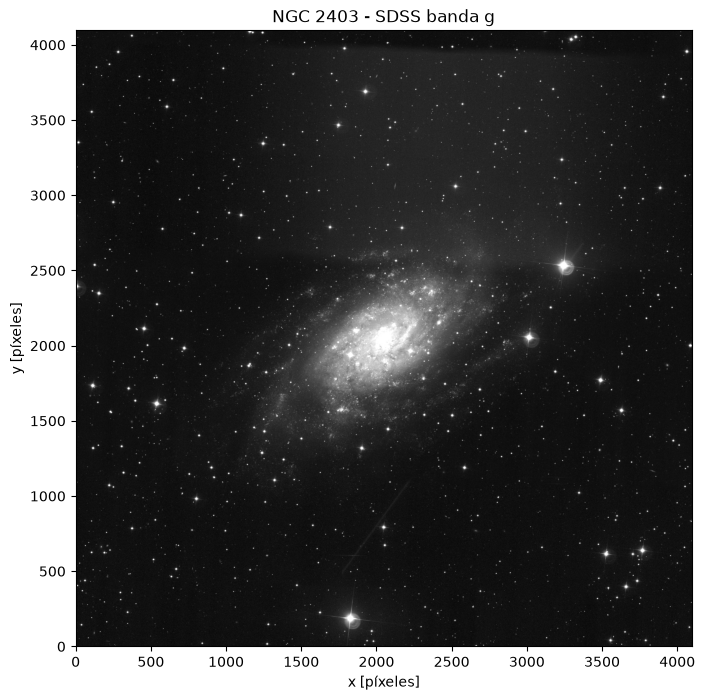

In [8]:
# Normalización para visualizar la galaxia
intervalo = PercentileInterval(99.5)
#intervalo = ZScaleInterval()
vmin, vmax = intervalo.get_limits(imagen)

norm = ImageNormalize(
    vmin=vmin,
    vmax=vmax,
    stretch=AsinhStretch()
)

plt.figure(figsize=(8, 8))

plt.imshow(
    imagen,
    origin="lower",
    cmap="gray",
    norm=norm
)

plt.xlabel("x [píxeles]")
plt.ylabel("y [píxeles]")
plt.title("NGC 2403 - SDSS banda g")

plt.show()

### Representación en coordenadas celestes

La información WCS contenida en la cabecera FITS permite asociar cada píxel de la imagen con una posición sobre el cielo. Por ello, además de visualizar la galaxia en coordenadas del detector, se representa la misma observación utilizando ascensión recta $\alpha$ y declinación $\delta$.


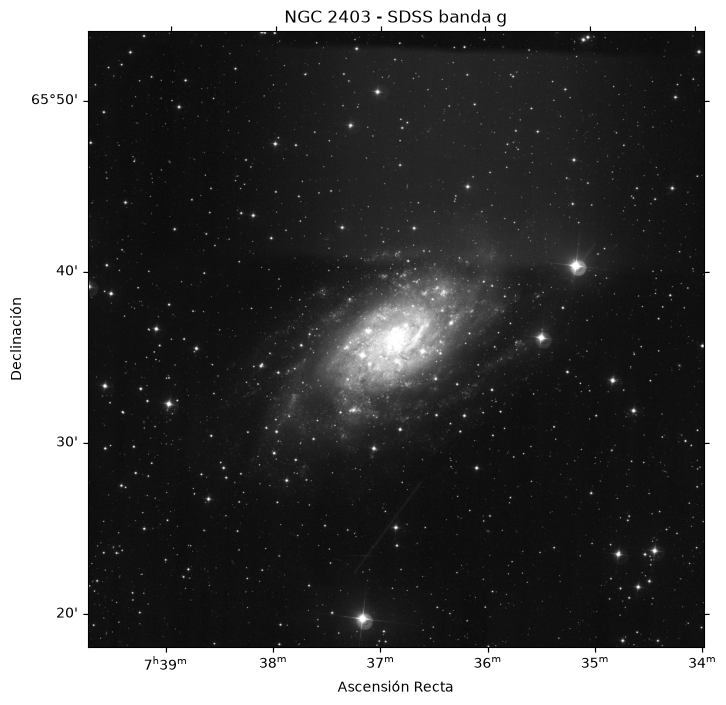

In [9]:
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection=wcs)

ax.imshow(
    imagen,
    origin="lower",
    cmap="gray",
    norm=norm
)

ax.set_xlabel("Ascensión Recta")
ax.set_ylabel("Declinación")
ax.set_title("NGC 2403 - SDSS banda g")

plt.show()

Como primera aproximación determinamos manualmente el centro aparente de NGC 2403 utilizando **SAOImage DS9**, obteniendo las coordenadas celestes

$$
\alpha = 07^{\rm h}36^{\rm m}50.7479^{\rm s},
$$

$$
\delta = +65^\circ36'14.592''.
$$

Estas coordenadas se expresan en el sistema de referencia ICRS. Sin embargo, el ajuste de isófotas se realiza directamente sobre la matriz de la imagen, por lo que es necesario transformar la posición celeste $(\alpha,\delta)$ a coordenadas de píxel $(x_0,y_0)$.

La transformación se realiza utilizando la información WCS almacenada en la cabecera del archivo FITS:

$$
(\alpha,\delta)
\longrightarrow
(x_0,y_0).
$$

Para esta imagen se obtiene aproximadamente

$$
x_0 \simeq 2054.19,
\qquad
y_0 \simeq 2054.19
$$

píxeles.


In [11]:
# Centro aproximado obtenido manualmente en DS9
centro_ds9 = SkyCoord(
    "07h36m50.7479s",
    "+65d36m14.592s",
    frame="icrs"
)

# Conversión de coordenadas celestes a píxeles
x0, y0 = wcs.world_to_pixel(centro_ds9)

print(f"x0 = {x0:.2f} píxeles")
print(f"y0 = {y0:.2f} píxeles")

x0 = 2054.19 píxeles
y0 = 2054.19 píxeles


### Definición de la geometría inicial

Además del centro, el algoritmo de ajuste necesita una geometría elíptica inicial que sirva como punto de partida. Esta geometría se caracteriza mediante el semieje mayor $a$, el semieje menor $b$, la elipticidad $\epsilon$ y el ángulo de posición $PA$.

![](./datos/f_elipse.png)

A partir de una estimación visual realizada previamente en DS9 se toman los semiejes aparentes de la galaxia,

$$
a_{\rm DS9}=0.1391721^\circ,
\qquad
b_{\rm DS9}=0.0711894^\circ.
$$

La elipticidad se define como

$$
\epsilon = 1-\frac{b}{a}.
$$

Por tanto, para los valores medidos se obtiene

$$
\epsilon \approx 0.488.
$$

Una elipticidad distinta de cero indica que la proyección de NGC 2403 sobre el plano del cielo no es circular. En una galaxia de disco, esta forma elíptica está relacionada principalmente con la inclinación del disco con respecto a la línea de visión.

Para iniciar el ajuste se adopta además un semieje mayor de

$$
a_{\rm inicial}=100\ {\rm píxeles}
$$

y un ángulo de posición inicial

$$
PA_{\rm inicial}=35^\circ.
$$

Con estos parámetros y el centro estimado anteriormente se construye un objeto `EllipseGeometry`, que constituye la geometría de referencia a partir de la cual `photutils` comenzará a ajustar las isófotas de la galaxia.q

In [12]:
a_ds9 = 0.1391721   # grados
b_ds9 = 0.0711894   # grados

eps_inicial = 1 - b_ds9 / a_ds9

print(f"Elipticidad inicial = {eps_inicial:.3f}")

Elipticidad inicial = 0.488


In [13]:
sma_inicial = 100.0  # semieje mayor inicial, en píxeles

pa_inicial = np.deg2rad(35.0)

In [14]:
geometria_inicial = EllipseGeometry(
    x0=x0,
    y0=y0,
    sma=sma_inicial,
    eps=eps_inicial,
    pa=pa_inicial
)

print("Centro inicial:")
print(f"x0 = {geometria_inicial.x0:.2f}")
print(f"y0 = {geometria_inicial.y0:.2f}")

print(f"\nSemieje mayor inicial = {geometria_inicial.sma:.1f} pix")
print(f"Elipticidad inicial = {geometria_inicial.eps:.3f}")
print(
    f"PA inicial = {np.rad2deg(geometria_inicial.pa):.1f} grados"
)

Centro inicial:
x0 = 2054.19
y0 = 2054.19

Semieje mayor inicial = 100.0 pix
Elipticidad inicial = 0.488
PA inicial = 35.0 grados


### Verificación de la geometría inicial

Antes de iniciar el ajuste automático de las isófotas se representa la geometría inicial sobre la imagen de NGC 2403.

La cruz indica la posición adoptada inicialmente para el centro $(x_0,y_0)$, mientras que la elipse representa los valores iniciales de semieje mayor, elipticidad y ángulo de posición.

Esta comprobación permite verificar visualmente que la condición inicial es razonable y que la elipse se encuentra aproximadamente centrada y orientada siguiendo la distribución general de luz de la galaxia.

No se pretende que esta primera elipse describa exactamente una isófota de NGC 2403; su función es proporcionar al algoritmo un punto de partida suficientemente cercano a la geometría real para que el proceso iterativo pueda converger correctamente.

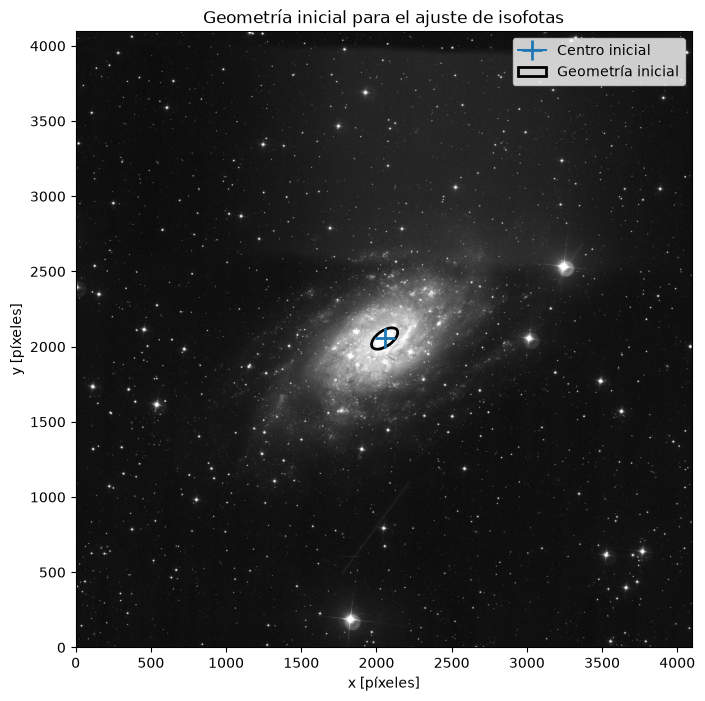

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(
    imagen,
    origin="lower",
    cmap="gray",
    norm=norm
)

# Centro inicial
ax.plot(
    x0,
    y0,
    marker="+",
    markersize=15,
    markeredgewidth=2,
    label="Centro inicial"
)

# Semiejes de la geometría inicial
a = geometria_inicial.sma
b = a * (1 - geometria_inicial.eps)

# Elipse inicial
elipse_plot = MplEllipse(
    (geometria_inicial.x0, geometria_inicial.y0),
    width=2 * a,
    height=2 * b,
    angle=np.rad2deg(geometria_inicial.pa),
    fill=False,
    linewidth=2,
    label="Geometría inicial"
)

ax.add_patch(elipse_plot)

ax.set_xlabel("x [píxeles]")
ax.set_ylabel("y [píxeles]")
ax.set_title("Geometría inicial para el ajuste de isofotas")
ax.legend()

plt.show()

### Primer ajuste de isófotas elípticas


El procedimiento busca, para diferentes distancias al centro, la elipse que mejor representa una región de brillo aproximadamente constante. De esta manera, cada isófota queda caracterizada por parámetros como:

- el semieje mayor $a$;
- el centro $(x_0,y_0)$;
- la elipticidad $\epsilon$;
- el ángulo de posición $PA$;
- la intensidad media $I(a)$ medida sobre la elipse.

El ajuste comienza en $a_0 = 100\ {\rm píxeles}$ y explora aproximadamente el intervalo

$$
10 \leq a \leq 1000\ {\rm píxeles}.
$$


En esta primera ejecución se dejan libres el centro, la elipticidad y el ángulo de posición para estudiar cómo cambia la geometría aparente de NGC 2403 con la distancia al centro galáctico.

También se aplica un rechazo iterativo de valores discrepantes mediante un *sigma clipping* de $3\sigma$. Este procedimiento ayuda a reducir la influencia de píxeles que no representan adecuadamente la distribución suave de luz de la galaxia, por ejemplo fuentes puntuales o regiones particularmente brillantes.


In [17]:
elipse = Ellipse(
    imagen,
    geometry=geometria_inicial
)

In [18]:
isofotas = elipse.fit_image(
    sma0=sma_inicial,
    minsma=10,
    maxsma=1000,
    step=0.1,
    sclip=3.0,
    n_clip=3,
    fix_center=False,
    fix_pa=False,
    fix_eps=False
)

print("Número de isofotas ajustadas:", len(isofotas))

Número de isofotas ajustadas: 49


### Extracción de los parámetros de las isófotas

Una vez realizado el ajuste, se extraen los parámetros correspondientes a cada isófota para estudiar su comportamiento como función de la distancia al centro.

El semieje mayor $a$ se utiliza como coordenada radial del análisis. Para cada valor de $a$ se almacenan la intensidad media de la isófota $I(a)$, la posición de su centro $x_0(a), y_0(a)$, su elipticidad $\epsilon(a)$ y su ángulo de posición $PA(a)$.

El ángulo de posición obtenido por `photutils` se encuentra originalmente en radianes y se convierte a grados para facilitar su interpretación.

El comportamiento radial de estos parámetros permitirá evaluar si existe una región donde la geometría de las isófotas se estabiliza. Esto es importante porque las regiones internas pueden estar influenciadas por estructuras centrales, mientras que a grandes radios el ajuste puede verse afectado por el menor brillo superficial y por otras fuentes presentes en la imagen.

In [19]:
sma = np.array([iso.sma for iso in isofotas])
intensidad = np.array([iso.intens for iso in isofotas])

x0_iso = np.array([iso.x0 for iso in isofotas])
y0_iso = np.array([iso.y0 for iso in isofotas])

eps_iso = np.array([iso.eps for iso in isofotas])
pa_iso = np.rad2deg(
    np.array([iso.pa for iso in isofotas])
)

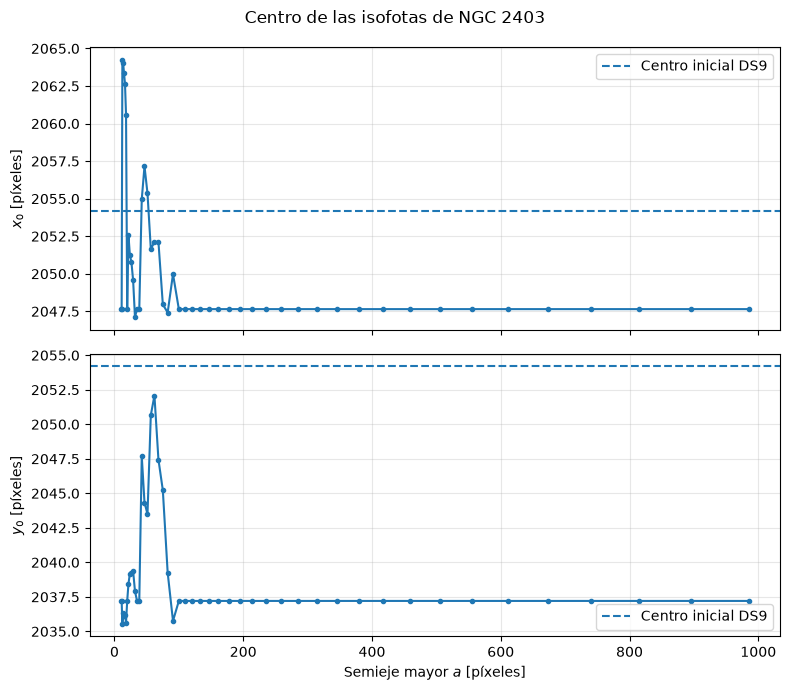

In [20]:
fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax[0].plot(sma, x0_iso, ".-")
ax[0].axhline(x0, linestyle="--", label="Centro inicial DS9")
ax[0].set_ylabel("$x_0$ [píxeles]")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(sma, y0_iso, ".-")
ax[1].axhline(y0, linestyle="--", label="Centro inicial DS9")
ax[1].set_xlabel("Semieje mayor $a$ [píxeles]")
ax[1].set_ylabel("$y_0$ [píxeles]")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.suptitle("Centro de las isofotas de NGC 2403")
plt.tight_layout()
plt.show()

### Diagnóstico de la calidad del ajuste

Antes de utilizar directamente los parámetros obtenidos es necesario comprobar la calidad y estabilidad de las isófotas ajustadas. Para ello se construye una tabla de diagnóstico que reúne, para cada semieje mayor, los parámetros geométricos obtenidos junto con información adicional proporcionada por el algoritmo.

En particular, se conserva el parámetro `stop_code`, que permite identificar cómo terminó el proceso iterativo correspondiente a cada isófota. Su distribución con el semieje mayor se inspecciona antes de seleccionar qué regiones de la galaxia serán utilizadas para estimar los parámetros geométricos definitivos.

También se registran `n_data` y `n_flag`, que permiten comparar la cantidad de puntos utilizados en cada isófota con aquellos que fueron marcados durante el procedimiento de ajuste.

Este diagnóstico es necesario porque una isófota calculada por el algoritmo no debe aceptarse automáticamente como una medición físicamente representativa. La estabilidad radial de los parámetros y el comportamiento del propio ajuste deben considerarse conjuntamente antes de determinar la geometría global de la galaxia.

In [21]:
diagnostico = pd.DataFrame({
    "sma": [iso.sma for iso in isofotas],
    "x0": [iso.x0 for iso in isofotas],
    "y0": [iso.y0 for iso in isofotas],
    "x0_err": [iso.x0_err for iso in isofotas],
    "y0_err": [iso.y0_err for iso in isofotas],
    "eps": [iso.eps for iso in isofotas],
    "pa_deg": [np.rad2deg(iso.pa) for iso in isofotas],
    "stop_code": [iso.stop_code for iso in isofotas],
    "valid": [iso.valid for iso in isofotas],
    "n_data": [iso.n_data for iso in isofotas],
    "n_flag": [iso.n_flag for iso in isofotas]
})

diagnostico

print(diagnostico["stop_code"].value_counts().sort_index())

stop_code
0    13
2     8
4    21
5     7
Name: count, dtype: int64


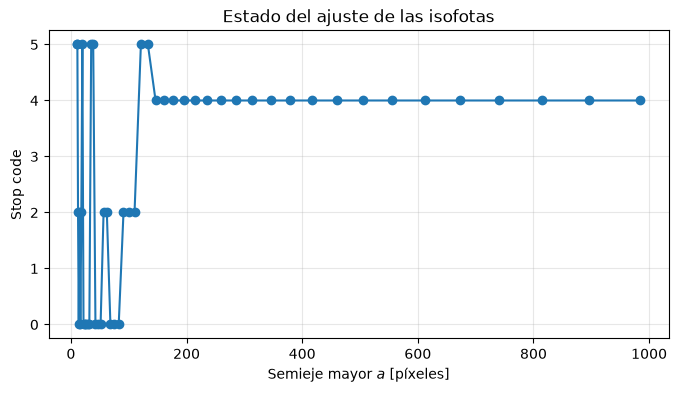

In [22]:
plt.figure(figsize=(8, 4))

plt.plot(
    diagnostico["sma"],
    diagnostico["stop_code"],
    "o-"
)

plt.xlabel("Semieje mayor $a$ [píxeles]")
plt.ylabel("Stop code")
plt.title("Estado del ajuste de las isofotas")
plt.grid(alpha=0.3)

plt.show()

### Estabilidad del centro en las isófotas convergentes

Para evaluar si el primer ajuste permite determinar un centro geométrico estable, se consideran inicialmente las isófotas cuyo proceso iterativo presenta convergencia normal.

A partir de estas se estudia la evolución de las coordenadas del centro, $x_0(a), y_0(a)$ como función del semieje mayor $a$. También se incluyen las incertidumbres estimadas por el ajuste para cada coordenada.

Si las isófotas estuvieran describiendo una distribución de luz perfectamente regular y concéntrica, se esperaría que los valores de $x_0$ y $y_0$ permanecieran aproximadamente constantes al aumentar el radio.

Sin embargo, los centros obtenidos presentan variaciones apreciables con $a$. Esto indica que permitir que el centro cambie libremente en cada isófota hace que el ajuste responda a diferentes estructuras presentes en la galaxia, en lugar de converger inmediatamente hacia una única posición representativa del centro global.

Por esta razón, el centro obtenido directamente de este primer ajuste no se adopta todavía como el centro fotométrico definitivo de NGC 2403.

In [23]:
ajustes_buenos = diagnostico[
    diagnostico["stop_code"] == 0
][
    ["sma", "x0", "y0", "x0_err", "y0_err", "eps", "pa_deg"]
]

ajustes_buenos

,sma,x0,y0,x0_err,y0_err,eps,pa_deg
3,13.513057,2064.023546,2036.348358,1.129457,0.572844,0.725721,15.707652
5,16.350799,2062.666004,2036.192111,0.423803,0.250084,0.704658,24.529852
8,21.762914,2052.562898,2038.449082,1.000311,0.467295,0.655334,168.358658
9,23.939205,2051.239641,2039.183449,1.531858,0.777155,0.582587,176.439525
10,26.333125,2050.784160,2039.226910,0.593504,0.346666,0.521822,7.287802
11,28.966438,2049.576447,2039.381393,0.648791,0.418293,0.479756,13.285807
12,31.863082,2047.120994,2037.917662,0.511226,0.455043,0.291888,30.723486
15,42.409762,2054.959371,2047.681646,0.990699,1.111542,0.516985,51.996836
16,46.650738,2057.163939,2044.330554,0.480085,0.533594,0.254281,60.677295
17,51.315812,2055.352038,2043.505108,0.467548,0.482501,0.244249,49.365291


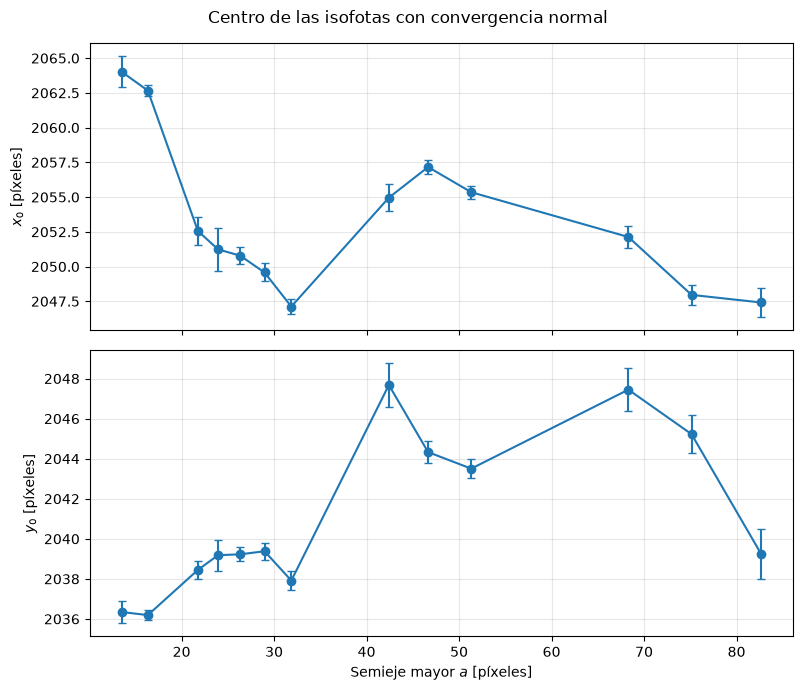

In [24]:
fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax[0].errorbar(
    ajustes_buenos["sma"],
    ajustes_buenos["x0"],
    yerr=ajustes_buenos["x0_err"],
    fmt="o-",
    capsize=3
)

ax[0].set_ylabel("$x_0$ [píxeles]")
ax[0].grid(alpha=0.3)

ax[1].errorbar(
    ajustes_buenos["sma"],
    ajustes_buenos["y0"],
    yerr=ajustes_buenos["y0_err"],
    fmt="o-",
    capsize=3
)

ax[1].set_xlabel("Semieje mayor $a$ [píxeles]")
ax[1].set_ylabel("$y_0$ [píxeles]")
ax[1].grid(alpha=0.3)

plt.suptitle("Centro de las isofotas con convergencia normal")
plt.tight_layout()
plt.show()

## Suavizado de la imagen para el análisis de la geometría global

NGC 2403 no presenta una distribución de brillo perfectamente suave. Al tratarse de una galaxia espiral, la imagen contiene estructuras de pequeña escala asociadas, entre otras cosas, con los brazos espirales, regiones brillantes de formación estelar y fuentes compactas.

Estas estructuras pueden afectar el ajuste de las isófotas, especialmente cuando se permite que su centro, elipticidad y ángulo de posición varíen libremente. Una región localmente brillante puede desplazar la solución de una isófota respecto a la distribución global de luz de la galaxia.

Para reducir este efecto se construye una versión suavizada de la imagen mediante un filtro gaussiano con

$$
\sigma = 5\ {\rm píxeles}.
$$

El suavizado disminuye las variaciones espaciales de pequeña escala y permite resaltar mejor la componente de brillo más extendida de NGC 2403.

In [25]:
from scipy.ndimage import gaussian_filter

In [31]:
# Imagen suavizada para determinar la geometría global
imagen_suave = gaussian_filter(
    imagen,
    sigma=5
)

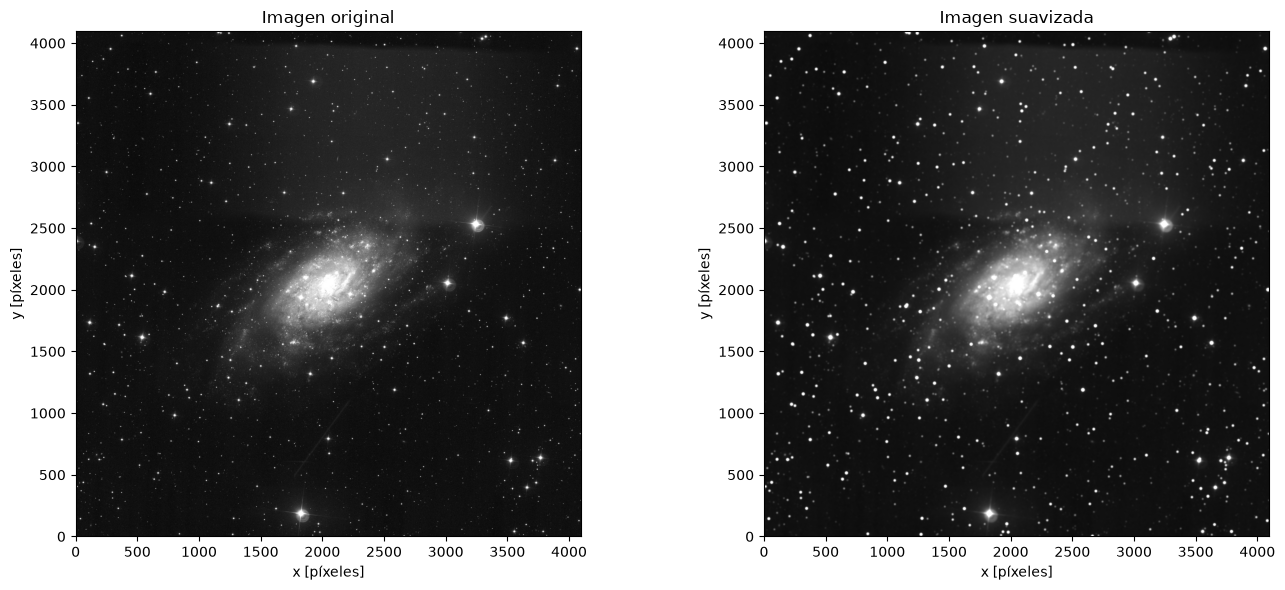

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(
    imagen,
    origin="lower",
    cmap="gray",
    norm=norm
)
ax[0].set_title("Imagen original")

ax[1].imshow(
    imagen_suave,
    origin="lower",
    cmap="gray",
    norm=norm
)
ax[1].set_title("Imagen suavizada")

for a in ax:
    a.set_xlabel("x [píxeles]")
    a.set_ylabel("y [píxeles]")

plt.tight_layout()
plt.show()

### Ajuste de isófotas sobre la imagen suavizada

Una vez reducida la influencia de las estructuras de pequeña escala, se repite el ajuste de isófotas utilizando la imagen suavizada.

Mantener una configuración equivalente al primer ajuste permite comparar directamente el comportamiento del algoritmo antes y después del suavizado.

En este caso se obtienen nuevamente 49 isófotas, pero el diagnóstico muestra una mejora importante en la convergencia: la mayor parte de las isófotas presenta ahora convergencia normal. Esto indica que la distribución suavizada de luz puede ser descrita de manera más estable mediante el modelo de isófotas elípticas.

Aun así, una mejor convergencia numérica no implica por sí sola que todos los parámetros representen directamente la geometría física global de la galaxia. Por esta razón se continúa examinando, en particular, el comportamiento del centro con el radio antes de adoptar una posición definitiva.

In [33]:
elipse_suave = Ellipse(
    imagen_suave,
    geometry=geometria_inicial
)

isofotas_suaves = elipse_suave.fit_image(
    sma0=sma_inicial,
    minsma=10,
    maxsma=1000,
    step=0.1,
    sclip=3.0,
    n_clip=3,
    fix_center=False,
    fix_pa=False,
    fix_eps=False
)

print("Número de isofotas:", len(isofotas_suaves))

Número de isofotas: 49


In [35]:
diagnostico_suave = pd.DataFrame({
    "sma": [iso.sma for iso in isofotas_suaves],
    "x0": [iso.x0 for iso in isofotas_suaves],
    "y0": [iso.y0 for iso in isofotas_suaves],
    "x0_err": [iso.x0_err for iso in isofotas_suaves],
    "y0_err": [iso.y0_err for iso in isofotas_suaves],
    "eps": [iso.eps for iso in isofotas_suaves],
    "pa_deg": [np.rad2deg(iso.pa) for iso in isofotas_suaves],
    "stop_code": [iso.stop_code for iso in isofotas_suaves],
    "valid": [iso.valid for iso in isofotas_suaves]
})

diagnostico_suave
print(diagnostico_suave["stop_code"].value_counts().sort_index())

stop_code
0    41
2     8
Name: count, dtype: int64


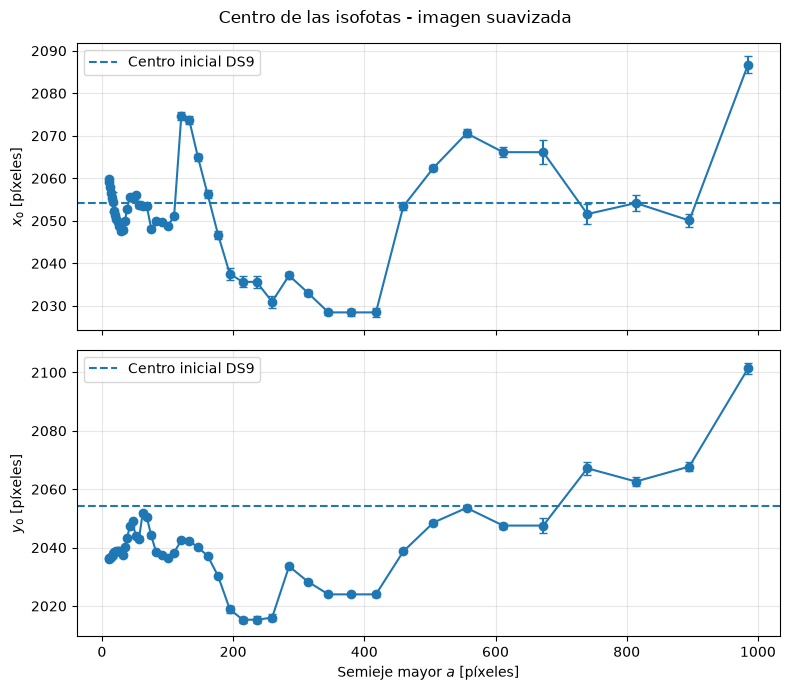

In [36]:
fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax[0].errorbar(
    diagnostico_suave["sma"],
    diagnostico_suave["x0"],
    yerr=diagnostico_suave["x0_err"],
    fmt="o-",
    capsize=3
)
ax[0].axhline(x0, linestyle="--", label="Centro inicial DS9")
ax[0].set_ylabel("$x_0$ [píxeles]")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].errorbar(
    diagnostico_suave["sma"],
    diagnostico_suave["y0"],
    yerr=diagnostico_suave["y0_err"],
    fmt="o-",
    capsize=3
)
ax[1].axhline(y0, linestyle="--", label="Centro inicial DS9")
ax[1].set_xlabel("Semieje mayor $a$ [píxeles]")
ax[1].set_ylabel("$y_0$ [píxeles]")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.suptitle("Centro de las isofotas - imagen suavizada")
plt.tight_layout()
plt.show()

### Determinación independiente del centro fotométrico

El ajuste de isófotas mostró que, incluso después de suavizar la imagen, permitir que el centro variara libremente producía desplazamientos con el radio. Esto sugiere que las estructuras no axisimétricas de NGC 2403 pueden influir sobre la posición determinada por cada isófota.

Por esta razón se realiza una estimación independiente del centro fotométrico utilizando únicamente la región central de la galaxia.

Como referencia inicial se conserva la posición estimada visualmente mediante DS9, y alrededor de ella se extrae inicialmente una región cuadrada con semitamaño de $150\ {\rm píxeles}$.

El análisis se realiza sobre la imagen suavizada, de forma que la determinación responda principalmente a la distribución global de luz de la región central y no a fuentes compactas o irregularidades de pequeña escala.

El recorte se inspecciona visualmente antes de calcular el centro para comprobar que la concentración central de luz se encuentra contenida adecuadamente dentro de la región seleccionada.

In [37]:
from photutils.centroids import centroid_2dg

Centro usado: 2054 2054
Dimensiones del recorte: (300, 300)


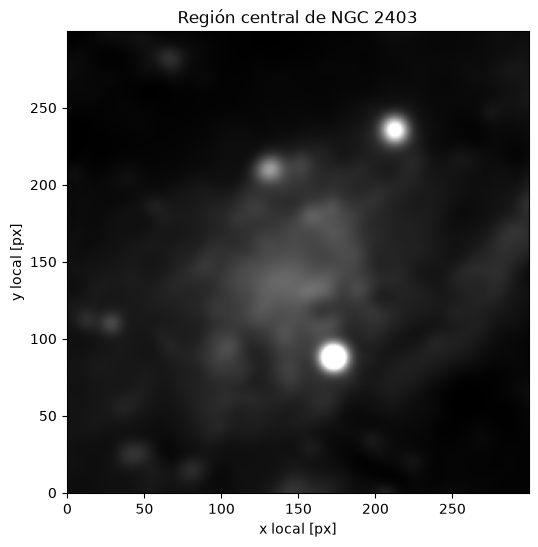

In [41]:
# Tamaño de la región central
half_size = 150

# Recuperar el centro inicial como valores escalares
x0_ds9 = float(np.asarray(geometria_inicial.x0).ravel()[0])
y0_ds9 = float(np.asarray(geometria_inicial.y0).ravel()[0])

# Convertir a índices enteros de píxel
xc0 = int(round(x0_ds9))
yc0 = int(round(y0_ds9))

# Recorte de la región central
recorte = imagen_suave[
    yc0-half_size:yc0+half_size,
    xc0-half_size:xc0+half_size
]

print("Centro usado:", xc0, yc0)
print("Dimensiones del recorte:", recorte.shape)

# Escala de visualización al 99.5%
intervalo_centro = PercentileInterval(99.5)
vmin_c, vmax_c = intervalo_centro.get_limits(recorte)

plt.figure(figsize=(6, 6))

plt.imshow(
    recorte,
    origin="lower",
    cmap="gray",
    vmin=vmin_c,
    vmax=vmax_c
)

plt.title("Región central de NGC 2403")
plt.xlabel("x local [px]")
plt.ylabel("y local [px]")

plt.show()

### Primera estimación mediante el centroide de la distribución de luz

Como primera aproximación se calcula el centro de intensidad de la región central mediante `centroid_com`.

Conceptualmente, este procedimiento corresponde a calcular un centro de masa utilizando la intensidad de cada píxel como peso. Para una distribución bidimensional de intensidad $I(x,y)$,

$$
x_c =
\frac{\sum I(x,y)x}
{\sum I(x,y)},
\qquad
y_c =
\frac{\sum I(x,y)y}
{\sum I(x,y)}.
$$

Antes de calcular el centroide se aplican algunas precauciones para reducir la influencia de valores que podrían sesgar el resultado. Se ignoran los píxeles no finitos, se limita el $1.5\%$ superior de la distribución de intensidades y se resta un nivel de fondo aproximado obtenido mediante la mediana del recorte.

Además, después de sustraer el fondo se eliminan los valores negativos para que únicamente la distribución positiva de luz contribuya al cálculo del centroide.

Finalmente, las coordenadas obtenidas dentro del recorte se transforman nuevamente al sistema de coordenadas de la imagen completa y se comparan con la estimación inicial realizada en DS9.

In [42]:
from photutils.centroids import centroid_com

# Copia del recorte
recorte_centro = recorte.copy()

# Ignorar píxeles no finitos
validos = np.isfinite(recorte_centro)

# Límite superior para evitar que estrellas muy brillantes dominen
limite_superior = np.nanpercentile(recorte_centro, 98.5)

# Recortamos únicamente los valores extremadamente brillantes
recorte_clip = np.where(
    validos,
    np.minimum(recorte_centro, limite_superior),
    0.0
)

# Quitamos un nivel de fondo aproximado
fondo = np.nanmedian(recorte_centro)
recorte_clip = recorte_clip - fondo

# No permitimos pesos negativos
recorte_clip[recorte_clip < 0] = 0

# Centroide de la distribución de luz
xc_local, yc_local = centroid_com(recorte_clip)

# Convertir nuevamente a coordenadas de la imagen completa
xc_centro = xc0 - half_size + xc_local
yc_centro = yc0 - half_size + yc_local

print(f"Centro local: ({xc_local:.2f}, {yc_local:.2f})")
print(f"Centro imagen completa: ({xc_centro:.2f}, {yc_centro:.2f})")
print(f"Centro inicial DS9: ({x0_ds9:.2f}, {y0_ds9:.2f})")

Centro local: (152.65, 137.88)
Centro imagen completa: (2056.65, 2041.88)
Centro inicial DS9: (2054.19, 2054.19)


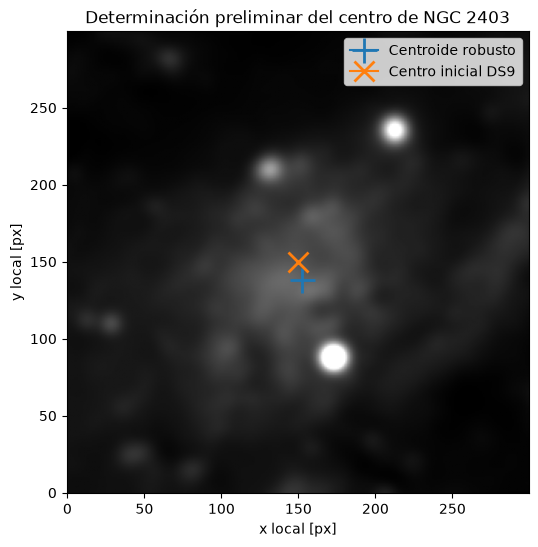

In [43]:
plt.figure(figsize=(6, 6))

plt.imshow(
    recorte,
    origin="lower",
    cmap="gray",
    vmin=vmin_c,
    vmax=vmax_c
)

plt.plot(
    xc_local,
    yc_local,
    marker="+",
    markersize=18,
    markeredgewidth=2,
    label="Centroide robusto"
)

plt.plot(
    half_size,
    half_size,
    marker="x",
    markersize=14,
    markeredgewidth=2,
    label="Centro inicial DS9"
)

plt.xlabel("x local [px]")
plt.ylabel("y local [px]")
plt.title("Determinación preliminar del centro de NGC 2403")
plt.legend()

plt.show()

### Prueba de estabilidad frente al tamaño de la región central

La posición obtenida mediante un centroide de intensidad puede depender del tamaño de la región utilizada. Esto es especialmente importante en una galaxia espiral, donde al aumentar la caja comienzan a incluirse brazos espirales, regiones de formación estelar y otras estructuras asimétricas.

Para comprobar esta dependencia se repite el cálculo del centro de luz utilizando varios semitamaños,

$$
100,\ 125,\ 150,\ 175,\ 200\ {\rm píxeles}.
$$

En cada caso se repite el mismo tratamiento: se limita la contribución de los píxeles extremadamente brillantes, se sustrae un nivel de fondo y se calcula el centroide de la distribución restante.

Una estimación robusta del centro debería presentar valores de $x_c$ y $y_c$ aproximadamente constantes al modificar moderadamente el tamaño de la región.

Las posiciones obtenidas se representan entonces como función del semitamaño de la caja para evaluar directamente su estabilidad.

In [44]:
from photutils.centroids import centroid_com

half_sizes = [100, 125, 150, 175, 200]

resultados_centro = []

for hs in half_sizes:

    # Recorte alrededor del centro inicial de DS9
    rec = imagen_suave[
        yc0-hs:yc0+hs,
        xc0-hs:xc0+hs
    ]

    # Píxeles válidos
    validos = np.isfinite(rec)

    # Limitar valores extremadamente brillantes
    limite_superior = np.nanpercentile(rec, 98.5)

    rec_clip = np.where(
        validos,
        np.minimum(rec, limite_superior),
        0.0
    )

    # Restar fondo
    fondo = np.nanmedian(rec)
    rec_clip = rec_clip - fondo
    rec_clip[rec_clip < 0] = 0

    # Centroide local
    xc_loc, yc_loc = centroid_com(rec_clip)

    # Pasar a coordenadas globales
    xc_global = xc0 - hs + xc_loc
    yc_global = yc0 - hs + yc_loc

    resultados_centro.append(
        [hs, xc_global, yc_global]
    )

resultados_centro = np.array(resultados_centro)

print(" half_size       x_c        y_c")

for hs, xcen, ycen in resultados_centro:
    print(f"{hs:8.0f}    {xcen:8.2f}   {ycen:8.2f}")

 half_size       x_c        y_c
     100     2057.14    2048.09
     125     2055.74    2045.21
     150     2056.65    2041.88
     175     2060.54    2031.84
     200     2052.31    2028.23


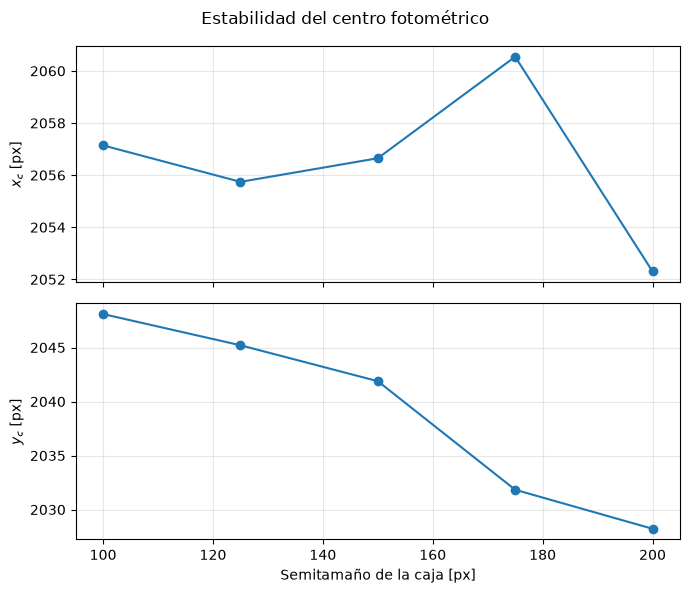

In [45]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

ax[0].plot(
    resultados_centro[:, 0],
    resultados_centro[:, 1],
    "o-"
)

ax[0].set_ylabel("$x_c$ [px]")
ax[0].grid(alpha=0.3)

ax[1].plot(
    resultados_centro[:, 0],
    resultados_centro[:, 2],
    "o-"
)

ax[1].set_xlabel("Semitamaño de la caja [px]")
ax[1].set_ylabel("$y_c$ [px]")
ax[1].grid(alpha=0.3)

plt.suptitle("Estabilidad del centro fotométrico")
plt.tight_layout()
plt.show()

#### Resultado de la prueba con el centro de luz

El centro obtenido mediante `centroid_com` muestra una dependencia apreciable con el tamaño de la región utilizada.

En particular, al aumentar el tamaño de la caja la coordenada $y_c$ presenta un desplazamiento sistemático, mientras que $x_c$ también muestra variaciones de varios píxeles.

Esto indica que el centro de intensidad está siendo afectado por la distribución asimétrica de luz alrededor del núcleo. Al incluir regiones progresivamente más externas, el centroide recibe una contribución creciente del disco y de las estructuras espirales.

Por tanto, el centro de luz no se adopta como estimación definitiva del centro fotométrico. En su lugar se utiliza a continuación un ajuste bidimensional de la concentración central de luz, que permite determinar de forma más localizada la posición del máximo de la componente central suavizada.

In [46]:
# Región central relativamente compacta
half_size = 100

recorte_centro = imagen_suave[
    yc0-half_size:yc0+half_size,
    xc0-half_size:xc0+half_size
].copy()

# Máscara de valores no válidos
mask = ~np.isfinite(recorte_centro)

# Enmascarar también los píxeles extremadamente brillantes
# para reducir el efecto de estrellas de campo
limite = np.nanpercentile(recorte_centro, 99.0)
mask |= recorte_centro > limite

# Centro mediante ajuste gaussiano 2D
xc_local_2dg, yc_local_2dg = centroid_2dg(
    recorte_centro,
    mask=mask
)

# Coordenadas globales
xc_2dg = xc0 - half_size + xc_local_2dg
yc_2dg = yc0 - half_size + yc_local_2dg

print(f"Centro local 2DG: ({xc_local_2dg:.2f}, {yc_local_2dg:.2f})")
print(f"Centro global 2DG: ({xc_2dg:.2f}, {yc_2dg:.2f})")
print(f"Centro inicial DS9: ({x0_ds9:.2f}, {y0_ds9:.2f})")

Centro local 2DG: (99.96, 88.07)
Centro global 2DG: (2053.96, 2042.07)
Centro inicial DS9: (2054.19, 2054.19)


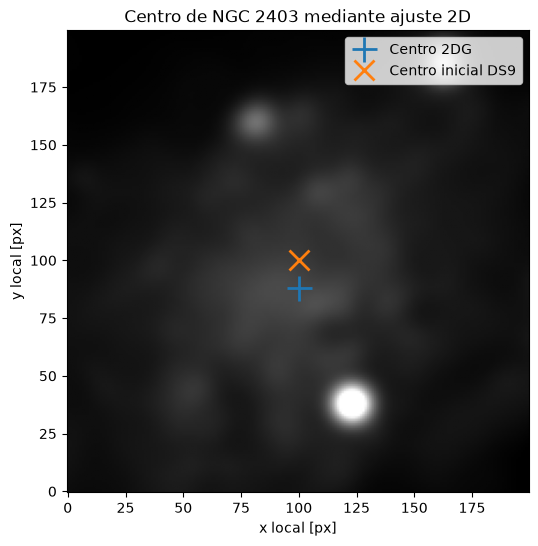

In [47]:
intervalo_centro = PercentileInterval(99.5)
vmin_c, vmax_c = intervalo_centro.get_limits(recorte_centro)

plt.figure(figsize=(6, 6))

plt.imshow(
    recorte_centro,
    origin="lower",
    cmap="gray",
    vmin=vmin_c,
    vmax=vmax_c
)

plt.plot(
    xc_local_2dg,
    yc_local_2dg,
    "+",
    markersize=18,
    markeredgewidth=2,
    label="Centro 2DG"
)

plt.plot(
    half_size,
    half_size,
    "x",
    markersize=14,
    markeredgewidth=2,
    label="Centro inicial DS9"
)

plt.xlabel("x local [px]")
plt.ylabel("y local [px]")
plt.title("Centro de NGC 2403 mediante ajuste 2D")
plt.legend()

plt.show()

### Determinación del centro mediante un ajuste gaussiano bidimensional

Debido a la dependencia del centro de luz con el tamaño de la región analizada, se adopta un segundo procedimiento para localizar de manera más estable la concentración central de NGC 2403.

Para ello se utiliza `centroid_2dg`, que determina el centro ajustando una distribución gaussiana bidimensional a la intensidad de la región central. De forma esquemática, una distribución gaussiana bidimensional puede escribirse como

$$
I(x,y)
=
I_0
\exp\left[
-\frac{1}{2}
\left(
\frac{(x-x_c)^2}{\sigma_x^2}
+
\frac{(y-y_c)^2}{\sigma_y^2}
\right)
\right],
$$

donde $(x_c,y_c)$ representa la posición central del modelo.

No se asume que toda la estructura central de la galaxia sea exactamente gaussiana. El ajuste se utiliza como una herramienta para localizar de manera robusta el máximo de la distribución suavizada de luz, disminuyendo la influencia de las estructuras más externas del disco.

Inicialmente se utiliza una región relativamente compacta con semitamaño $h=100\ {\rm píxeles}$ alrededor de la posición estimada en DS9.

También se enmascaran los píxeles no finitos y aquellos por encima del percentil 99 de intensidad, con el objetivo de reducir la influencia de estrellas de campo o fuentes compactas extremadamente brillantes.

In [58]:
from photutils.centroids import centroid_2dg

half_sizes_2dg = [60, 80, 100, 120, 130]

resultados_2dg = []

for hs in half_sizes_2dg:

    # Recorte alrededor del centro inicial de DS9
    rec = imagen_suave[
        yc0-hs:yc0+hs,
        xc0-hs:xc0+hs
    ].copy()

    # Máscara de valores no finitos
    mask = ~np.isfinite(rec)

    # Enmascarar los píxeles extremadamente brillantes
    limite = np.nanpercentile(rec, 99.0)
    mask |= rec > limite

    # Ajuste gaussiano bidimensional
    xc_loc, yc_loc = centroid_2dg(
        rec,
        mask=mask
    )

    # Coordenadas globales
    xc_global = xc0 - hs + xc_loc
    yc_global = yc0 - hs + yc_loc

    resultados_2dg.append(
        [hs, xc_global, yc_global]
    )

resultados_2dg = np.array(resultados_2dg)

print("half_size       x_c       y_c")

for hs, xc, yc in resultados_2dg:
    print(f"{hs:8.0f}    {xc:8.2f}  {yc:8.2f}")

half_size       x_c       y_c
      60     2051.84   2041.10
      80     2053.11   2040.09
     100     2053.96   2042.07
     120     2052.88   2041.16
     130     2052.35   2040.42


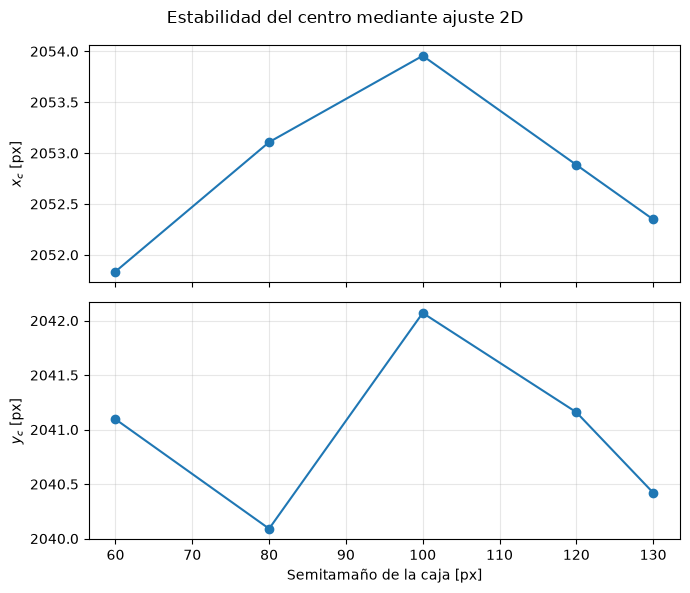

In [59]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

ax[0].plot(
    resultados_2dg[:, 0],
    resultados_2dg[:, 1],
    "o-"
)

ax[0].set_ylabel("$x_c$ [px]")
ax[0].grid(alpha=0.3)

ax[1].plot(
    resultados_2dg[:, 0],
    resultados_2dg[:, 2],
    "o-"
)

ax[1].set_xlabel("Semitamaño de la caja [px]")
ax[1].set_ylabel("$y_c$ [px]")
ax[1].grid(alpha=0.3)

plt.suptitle("Estabilidad del centro mediante ajuste 2D")
plt.tight_layout()
plt.show()

Dado que las posiciones obtenidas mediante el ajuste bidimensional permanecen aproximadamente estables para los diferentes tamaños de caja, se utiliza el conjunto de estas mediciones para definir el centro fotométrico final.

Para disminuir la sensibilidad frente a algún ajuste individual se adopta la mediana de las posiciones, y como estimación de la variabilidad del procedimiento se calcula además la desviación estándar de las posiciones obtenidas al modificar el tamaño de la región.

El centro fotométrico adoptado es

$$
\boxed{
x_c = 2052.88 \pm 0.80\ {\rm px}
}
$$

$$
\boxed{
y_c = 2041.10 \pm 0.76\ {\rm px}
}
$$

Las dispersiones son menores que un píxel, lo que muestra que la posición determinada mediante este procedimiento es estable frente a cambios moderados en el tamaño de la región utilizada para el ajuste.

In [60]:
# Centro fotométrico final: mediana de los ajustes 2D
xc_final = np.median(resultados_2dg[:, 1])
yc_final = np.median(resultados_2dg[:, 2])

# Dispersión entre las distintas cajas
sigma_x = np.std(resultados_2dg[:, 1], ddof=1)
sigma_y = np.std(resultados_2dg[:, 2], ddof=1)

print(f"Centro fotométrico final:")
print(f"x_c = {xc_final:.2f} ± {sigma_x:.2f} px")
print(f"y_c = {yc_final:.2f} ± {sigma_y:.2f} px")

Centro fotométrico final:
x_c = 2052.88 ± 0.80 px
y_c = 2041.10 ± 0.76 px


Una vez determinada la posición final del centro en coordenadas de píxel, se utiliza nuevamente la solución WCS de la imagen para transformarla a coordenadas celestes:

$$
(x_c,y_c)
\longrightarrow
(\alpha_c,\delta_c).
$$

Para el centro fotométrico adoptado se obtiene

$$
\boxed{
\alpha_c =
07^{\rm h}36^{\rm m}50.86^{\rm s}
}
$$

y

$$
\boxed{
\delta_c =
+65^\circ36'07.7''
}.
$$

De esta manera, la posición determinada a partir de la distribución de luz de la imagen puede expresarse en el sistema de coordenadas astronómicas y utilizarse posteriormente como referencia para los demás parámetros estructurales de NGC 2403.

In [61]:
centro_cielo = wcs.celestial.pixel_to_world(
    xc_final,
    yc_final
)

print(
    "RA =",
    centro_cielo.ra.to_string(
        unit=u.hourangle,
        sep=":",
        precision=2
    )
)

print(
    "Dec =",
    centro_cielo.dec.to_string(
        unit=u.deg,
        sep=":",
        precision=1,
        alwayssign=True
    )
)

RA = 7:36:50.86
Dec = +65:36:07.7


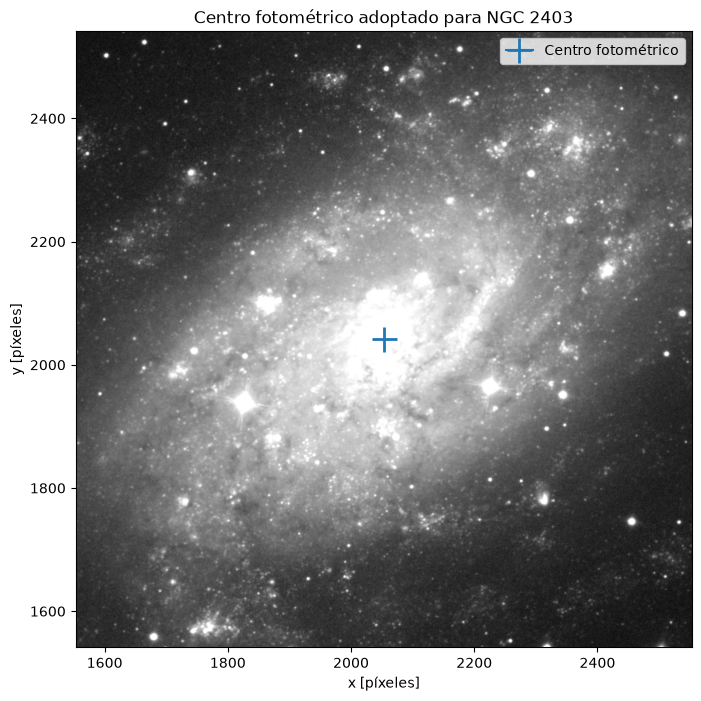

In [62]:
plt.figure(figsize=(8, 8))

plt.imshow(
    imagen,
    origin="lower",
    cmap="gray",
    norm=norm
)

plt.plot(
    xc_final,
    yc_final,
    marker="+",
    markersize=18,
    markeredgewidth=2,
    label="Centro fotométrico"
)

plt.xlim(xc_final - 500, xc_final + 500)
plt.ylim(yc_final - 500, yc_final + 500)

plt.xlabel("x [píxeles]")
plt.ylabel("y [píxeles]")
plt.title("Centro fotométrico adoptado para NGC 2403")
plt.legend()

plt.show()

## Estimación de la inclinación de la galaxia

Para estimar la inclinación de NGC 2403 se analiza la geometría aparente de las isófotas correspondientes principalmente al disco.

El centro fotométrico ya fue determinado de manera independiente en la sección anterior, por lo que en este nuevo ajuste se mantiene fijo en $(x_c,y_c)=(2052.88,\;2041.10)\ {\rm px}$.

Esto evita que las irregularidades del disco desplacen nuevamente el centro durante el ajuste y permite concentrar el análisis en los parámetros geométricos que describen la orientación aparente de la galaxia.

Se adopta inicialmente un semieje mayor de $a_0=500\ {\rm píxeles}$ y se ajustan isófotas en el intervalo aproximado

$$
250 \leq a \leq 1000\ {\rm píxeles}.
$$

En cada isófota se mantiene fijo el centro, mientras que la elipticidad y el ángulo de posición pueden variar libremente. El ajuste se realiza sobre la imagen suavizada para reducir la influencia de estructuras locales, como regiones brillantes y brazos espirales, y obtener una descripción más representativa de la geometría global del disco.

In [72]:
# Semieje mayor inicial para estudiar directamente el disco
sma_disco0 = 500.0

geometria_disco = EllipseGeometry(
    x0=xc_final,
    y0=yc_final,
    sma=sma_disco0,
    eps=eps_inicial,
    pa=pa_inicial
)

In [73]:
elipse_disco = Ellipse(
    imagen_suave,
    geometry=geometria_disco
)

isofotas_disco = elipse_disco.fit_image(
    sma0=sma_disco0,
    minsma=250,
    maxsma=1000,
    step=0.05,
    sclip=3.0,
    n_clip=3,

    fix_center=True,
    fix_pa=False,
    fix_eps=False
)

print("Número de isofotas:", len(isofotas_disco))

Número de isofotas: 29


### Diagnóstico de las isófotas del disco

El ajuste produce un conjunto de isófotas externas para las cuales se registran el semieje mayor, la elipticidad, el ángulo de posición y sus respectivas incertidumbres.

Antes de utilizar estos parámetros para determinar la inclinación se revisa nuevamente la calidad numérica del ajuste mediante `stop_code` y `valid`.

De las 29 isófotas obtenidas, 23 presentan convergencia normal y son consideradas válidas. Estas isófotas se conservan para estudiar cómo evolucionan con el radio

$$
\epsilon(a)
\qquad \text{y} \qquad
PA(a).
$$

La inspección radial de estos parámetros es importante porque las regiones internas pueden estar afectadas por la estructura central y los brazos espirales, mientras que las regiones demasiado externas presentan menor brillo superficial. Se busca, por tanto, una región del disco donde la geometría sea suficientemente estable para representar su orientación global.

In [74]:
diag_disco = pd.DataFrame({
    "sma": [iso.sma for iso in isofotas_disco],
    "eps": [iso.eps for iso in isofotas_disco],
    "eps_err": [iso.ellip_err for iso in isofotas_disco],
    "pa_deg": [np.rad2deg(iso.pa) for iso in isofotas_disco],
    "pa_err_deg": [np.rad2deg(iso.pa_err) for iso in isofotas_disco],
    "stop_code": [iso.stop_code for iso in isofotas_disco],
    "valid": [iso.valid for iso in isofotas_disco]
})

print(
    diag_disco["stop_code"]
    .value_counts()
    .sort_index()
)

stop_code
0    23
2     6
Name: count, dtype: int64


In [75]:
disco_bueno = diag_disco[
    (diag_disco["stop_code"] == 0) &
    (diag_disco["valid"] == True)
].copy()

print(
    "Isofotas externas con convergencia normal:",
    len(disco_bueno)
)

Isofotas externas con convergencia normal: 23


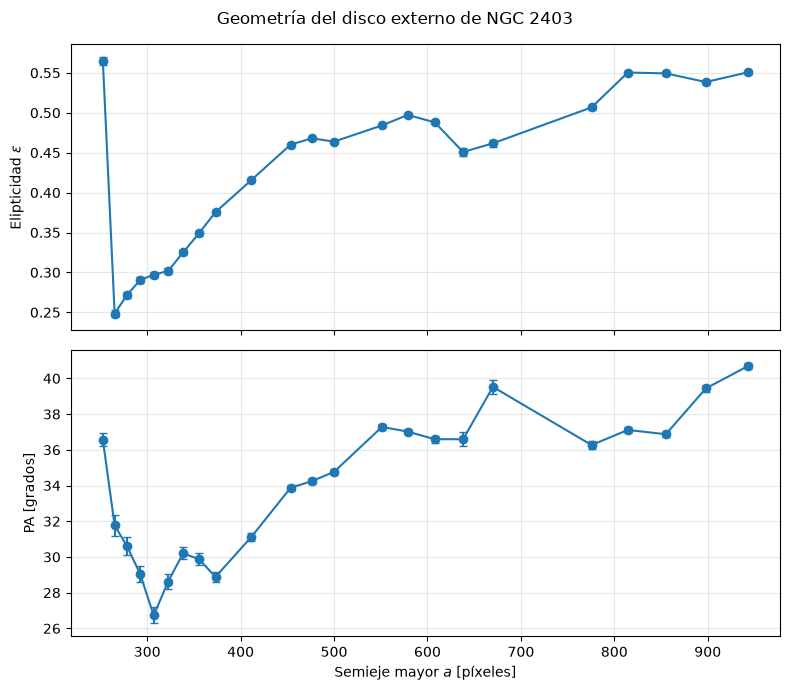

In [76]:
fig, ax = plt.subplots(
    2, 1,
    figsize=(8, 7),
    sharex=True
)

ax[0].errorbar(
    disco_bueno["sma"],
    disco_bueno["eps"],
    yerr=disco_bueno["eps_err"],
    fmt="o-",
    capsize=3
)

ax[0].set_ylabel(r"Elipticidad $\epsilon$")
ax[0].grid(alpha=0.3)

ax[1].errorbar(
    disco_bueno["sma"],
    disco_bueno["pa_deg"],
    yerr=disco_bueno["pa_err_deg"],
    fmt="o-",
    capsize=3
)

ax[1].set_xlabel("Semieje mayor $a$ [píxeles]")
ax[1].set_ylabel("PA [grados]")
ax[1].grid(alpha=0.3)

plt.suptitle(
    "Geometría del disco externo de NGC 2403"
)

plt.tight_layout()
plt.show()

### Selección de una región representativa

A partir del comportamiento radial de la elipticidad y del ángulo de posición se selecciona una región externa del disco comprendida entre

$$
800 \leq a \leq 950\ {\rm píxeles}.
$$

En este intervalo se dispone de cuatro isófotas con convergencia normal. Sus elipticidades se encuentran alrededor de

$$
\epsilon \sim 0.55,
$$

mientras que el ángulo de posición permanece aproximadamente entre $37^\circ$ y $41^\circ$.

Esta región se utiliza para estimar la forma proyectada del disco evitando depender de una única isófota. Como valor representativo se empleará la mediana de las mediciones realizadas en este intervalo.

In [77]:
zona_inclinacion = disco_bueno[
    (disco_bueno["sma"] >= 800) &
    (disco_bueno["sma"] <= 950)
].copy()

zona_inclinacion[
    ["sma", "eps", "eps_err", "pa_deg", "pa_err_deg"]
]

,sma,eps,eps_err,pa_deg,pa_err_deg
24,814.447313,0.550417,0.002479,37.112832,0.180103
25,855.169679,0.549321,0.002311,36.873289,0.170742
26,897.928163,0.538511,0.002321,39.437432,0.172405
27,942.824571,0.550634,0.002287,40.681741,0.169674


### Cálculo de la inclinación a partir de la relación de ejes

La elipticidad de una isófota se define como

$$
\epsilon = 1-\frac{b}{a},
$$

donde $a$ y $b$ son los semiejes mayor y menor de la elipse proyectada. Por tanto, la relación de ejes aparente es

$$
q=\frac{b}{a}=1-\epsilon.
$$

Se adopta como elipticidad representativa del disco la mediana de las isófotas seleccionadas:

$$
\epsilon_{\rm disco}=0.5499.
$$

De esta manera,

$$
q_{\rm disco}=1-\epsilon_{\rm disco}
             =0.4501.
$$

Bajo la aproximación de que el disco es intrínsecamente circular y geométricamente delgado, su proyección sobre el plano del cielo satisface

$$
\frac{b}{a}=\cos i,
$$

donde $i$ es el ángulo de inclinación. Por tanto,

$$
i=
\arccos\left(\frac{b}{a}\right)
=
\arccos(q_{\rm disco}).
$$

Con la relación de ejes medida se obtiene

$$
\boxed{i=63.25^\circ}.
$$

En esta convención, $i=0^\circ$ corresponde a una galaxia observada de frente (*face-on*), mientras que $i=90^\circ$ corresponde a un disco observado de canto (*edge-on*). Por lo tanto, NGC 2403 presenta una inclinación intermedia-alta respecto a la línea de visión.

In [ ]:
eps_disco = np.median(zona_inclinacion["eps"])

q_disco = 1 - eps_disco

inclinacion = np.degrees(
    np.arccos(q_disco)
)

pa_disco = np.median(
    zona_inclinacion["pa_deg"] + 90
)

print(f"Elipticidad representativa = {eps_disco:.4f}")
print(f"Relación de ejes b/a = {q_disco:.4f}")
print(f"Inclinación = {inclinacion:.2f} grados")

Elipticidad representativa = 0.5499
Relación de ejes b/a = 0.4501
Inclinación = 63.25 grados


### Dispersión e incertidumbre asociada

La variación de la elipticidad entre las isófotas seleccionadas se utiliza como una estimación de la dispersión del valor representativo. Se obtiene

$$
\sigma_{\epsilon}=0.0058.
$$

Como

$$
i=\arccos(1-\epsilon),
$$

la incertidumbre se propaga utilizando

$$
\sigma_i
\simeq
\left|
\frac{di}{d\epsilon}
\right|
\sigma_\epsilon.
$$

Dado que

$$
q=1-\epsilon,
$$

resulta

$$
\sigma_i
=
\frac{\sigma_\epsilon}
{\sqrt{1-q^2}},
$$

expresada inicialmente en radianes y posteriormente convertida a grados.

El resultado final es

$$
\boxed{
\epsilon = 0.5499 \pm 0.0058
}
$$

y

$$
\boxed{
i = 63.25^\circ \pm 0.37^\circ
}.
$$

La incertidumbre reportada representa principalmente la dispersión de la geometría medida entre las diferentes isófotas de la región seleccionada, y no debe interpretarse como un error estadístico completo que incluya todas las posibles fuentes sistemáticas del modelo.

In [131]:
sigma_eps = np.std(
    zona_inclinacion["eps"],
    ddof=1
)

# Propagación de incertidumbre
sigma_i = np.degrees(
    sigma_eps / np.sqrt(1 - q_disco**2)
)

sigma_pa = np.std(
    zona_inclinacion["pa_deg"],
    ddof=1
)

print(f"epsilon = {eps_disco:.4f} ± {sigma_eps:.4f}")
print(f"i = {inclinacion:.2f} ± {sigma_i:.2f} grados")
print(f"PA(real) = {pa_disco:.2f} ± {sigma_pa:.2f} grados")

epsilon = 0.5499 ± 0.0058
i = 63.25 ± 0.37 grados
PA(real) = 128.28 ± 1.84 grados


## Distribución de brillo superficial

En las secciones anteriores se determinaron de manera independiente el centro fotométrico y la geometría representativa del disco. Por ello, para el análisis fotométrico se adoptan como parámetros fijos:

$$
(x_c,y_c)=(2052.88,\;2041.10)\ {\rm px},
$$

$$
\epsilon = 0.5499,
$$

$$
\frac{b}{a}=1-\epsilon=0.4501,
$$

y

$$
PA = 38.28^\circ.
$$

La elipticidad y el ángulo de posición corresponden a los valores medianos obtenidos en la región externa seleccionada previamente como representativa del disco.

Mantener estos parámetros fijos permite que el cambio de intensidad medido entre una elipse y otra sea interpretado principalmente como una variación con la distancia galactocéntrica, y no como consecuencia de cambios simultáneos en el centro, la orientación o la forma de las isófotas.

De esta manera, el semieje mayor de cada elipse,

$$
R \equiv a,
$$

se utilizará como coordenada radial para construir el perfil fotométrico de NGC 2403.

In [81]:
# Geometría representativa del disco externo

eps_disco = np.median(zona_inclinacion["eps"])
q_disco = 1 - eps_disco

pa_disco_deg = np.median(zona_inclinacion["pa_deg"])
pa_disco = np.deg2rad(pa_disco_deg)

print(f"Centro = ({xc_final:.2f}, {yc_final:.2f}) px")
print(f"Elipticidad = {eps_disco:.4f}")
print(f"b/a = {q_disco:.4f}")
print(f"PA = {pa_disco_deg:.2f} grados")

Centro = (2052.88, 2041.10) px
Elipticidad = 0.5499
b/a = 0.4501
PA = 38.28 grados


### Estimación del nivel de cielo

Antes de medir el perfil radial de intensidad es necesario estimar y sustraer el nivel de fondo de la imagen.

La señal registrada en cada píxel puede representarse esquemáticamente como

$$
I_{\rm obs}
=
I_{\rm galaxia}
+
I_{\rm cielo},
$$

por lo que la intensidad atribuida a la galaxia se obtiene mediante

$$
I_{\rm galaxia}
=
I_{\rm obs}
-
I_{\rm cielo}.
$$

El nivel de cielo se estima utilizando regiones exteriores de la imagen, tomando franjas de 400 píxeles de ancho en los cuatro bordes. Estas zonas permiten obtener una muestra amplia del fondo y disminuir la contribución de la región principal ocupada por la galaxia.

Debido a que las regiones exteriores también pueden contener estrellas de campo, fuentes compactas o píxeles anómalos, se utiliza `sigma_clipped_stats` con un rechazo de $3\sigma$ y un máximo de cinco iteraciones. Este procedimiento elimina iterativamente los valores más alejados de la distribución dominante y proporciona una estimación más precisa del fondo.

Para la sustracción se adopta la **mediana**, debido a que es menos sensible a valores extremos que la media.

In [89]:
from astropy.stats import sigma_clipped_stats

In [90]:
# Anchura de los bordes utilizados para estimar el cielo
borde = 400

# Extraemos las cuatro regiones exteriores de la imagen
pixeles_cielo = np.concatenate([
    imagen[:borde, :].ravel(),          # borde inferior
    imagen[-borde:, :].ravel(),         # borde superior
    imagen[borde:-borde, :borde].ravel(),   # izquierda
    imagen[borde:-borde, -borde:].ravel()   # derecha
])

# Estadística robusta con sigma clipping
media_cielo, mediana_cielo, sigma_cielo = sigma_clipped_stats(
    pixeles_cielo,
    sigma=3.0,
    maxiters=5
)

print(f"Media del cielo   = {media_cielo:.6f}")
print(f"Mediana del cielo = {mediana_cielo:.6f}")
print(f"Sigma del cielo   = {sigma_cielo:.6f}")

Media del cielo   = 0.004025
Mediana del cielo = 0.003115
Sigma del cielo   = 0.008812


En esta etapa el término *brillo superficial* se utiliza para describir el perfil de intensidad media sobre las isófotas. Los valores permanecen en las unidades de la imagen; no se ha realizado todavía una calibración fotométrica para expresarlos en ${\rm mag\,arcsec^{-2}}$.

In [91]:
imagen_sin_cielo = imagen - mediana_cielo

### Muestreo de la intensidad sobre elipses concéntricas

Para construir el perfil radial de intensidad se utiliza la imagen original con el cielo sustraído. La imagen suavizada empleada anteriormente fue útil para determinar parámetros geométricos globales, pero para realizar la medición fotométrica se conserva la información de intensidad presente en los datos originales.

Se generan elipses concéntricas con semiejes mayores comprendidos entre

$$
10 \leq a < 1100\ {\rm píxeles},
$$

utilizando incrementos de $\Delta a=10\ {\rm píxeles}$. En todas las elipses se mantienen fijos los parámetros previamente determinados:

$$
x_0=x_c,
\qquad
y_0=y_c,
\qquad
\epsilon=\epsilon_{\rm disco},
\qquad
PA=PA_{\rm disco}.
$$

Para cada radio se utiliza `EllipseSample` para muestrear los valores de intensidad a lo largo de la correspondiente elipse. Se emplea interpolación bilineal para estimar la intensidad cuando la trayectoria de la isófota no coincide exactamente con el centro de los píxeles.

También se aplica un rechazo iterativo de $3\sigma$ durante tres iteraciones para disminuir la influencia de valores atípicos, como estrellas de campo o regiones localmente muy brillantes.

La cantidad principal obtenida para cada elipse es la intensidad media

$$
I(a)
=
\left\langle I(x,y)\right\rangle_{\rm elipse},
$$

que proporciona una medida azimutalmente promediada de cómo cambia el brillo de la galaxia con la distancia al centro.

In [88]:
from photutils.isophote import EllipseSample

Como estimación de la incertidumbre estadística de la intensidad media se utiliza

$$
\sigma_{\bar I}
\simeq
\frac{s_I}{\sqrt{N}},
$$

donde $s_I$ es la desviación estándar de los valores finitos medidos sobre la elipse y $N$ es el número de puntos utilizados.

Esta cantidad representa un error estándar aproximado de la media. No incluye todas las posibles fuentes sistemáticas, como la incertidumbre en la estimación del cielo o la correlación entre píxeles vecinos.

Para cada radio se almacenan finalmente el semieje mayor, la intensidad media, su error aproximado y el número efectivo de puntos utilizados en el muestreo.

In [92]:
# Radios elípticos donde mediremos el brillo superficial
radios_px = np.arange(10, 1100, 10)

resultados_perfil = []

for sma in radios_px:

    # Geometría fija para este radio
    geometria = EllipseGeometry(
        x0=xc_final,
        y0=yc_final,
        sma=sma,
        eps=eps_disco,
        pa=pa_disco
    )

    # Muestreo de la imagen original con el cielo sustraído
    muestra = EllipseSample(
        imagen_sin_cielo,
        sma=sma,
        geometry=geometria,
        sclip=3.0,
        n_clip=3,
        integrmode="bilinear"
    )

    # Extraer intensidades y calcular propiedades
    muestra.update(
        fixed_parameters=[True, True, True, True]
    )

    # Intensidad media de la isofota
    intensidad_media = muestra.mean

    # Valores realmente utilizados
    valores = muestra.values[2]

    # Error estándar aproximado de la media
    valores_finitos = valores[np.isfinite(valores)]

    if len(valores_finitos) > 1:
        error_media = (
            np.std(valores_finitos, ddof=1)
            / np.sqrt(len(valores_finitos))
        )
    else:
        error_media = np.nan

    resultados_perfil.append([
        sma,
        intensidad_media,
        error_media,
        muestra.actual_points
    ])

In [93]:
perfil = pd.DataFrame(
    resultados_perfil,
    columns=[
        "sma_px",
        "I",
        "I_err",
        "n_puntos"
    ]
)

perfil.head()

,sma_px,I,I_err,n_puntos
0,10,1.633454,0.022278,41
1,20,1.565110,0.024684,80
2,30,1.474889,0.019118,119
3,40,1.321804,0.013597,157
4,50,1.211797,0.013935,201


### Conversión del radio de píxeles a segundos de arco

Inicialmente el perfil radial se encuentra expresado en función del semieje mayor medido en píxeles. Para proporcionar una escala angular con significado astronómico se utiliza nuevamente la información WCS contenida en la cabecera FITS.

A partir de la matriz de transformación WCS se obtiene una escala media de

$$
s = 0.5273\ {\rm arcsec\,pixel^{-1}}.
$$

Por tanto, cada semieje mayor medido en píxeles se transforma mediante

$$
R\,[{\rm arcsec}]
=
a\,[{\rm px}]
\,
s\,[{\rm arcsec\,px^{-1}}],
$$

es decir,

$$
R
=
0.5273\,a.
$$

El perfil puede entonces expresarse como

$$
I(R),
$$

donde $R$ representa el radio elíptico angular medido a lo largo del semieje mayor.

Esta conversión proporciona todavía una distancia angular sobre el cielo. Para expresar el radio en unidades físicas, como parsecs o kiloparsecs, sería necesario incorporar posteriormente la distancia a NGC 2403.

In [94]:
from astropy.wcs.utils import proj_plane_pixel_scales

# Escala angular de la imagen
escala_deg_pix = np.mean(
    proj_plane_pixel_scales(wcs.celestial)
)

escala_arcsec_pix = escala_deg_pix * 3600

print(
    f"Escala = {escala_arcsec_pix:.4f} arcsec/pixel"
)

# Radio angular
perfil["R_arcsec"] = (
    perfil["sma_px"] * escala_arcsec_pix
)

Escala = 0.5273 arcsec/pixel


### Perfil radial de intensidad de NGC 2403

Con las intensidades medidas sobre las elipses concéntricas y los radios expresados en segundos de arco, se construye el perfil radial $I(R)$ donde cada punto representa la intensidad media medida sobre una isófota de semieje mayor $R$. Las barras de error corresponden al error estándar aproximado calculado previamente para cada elipse,

$$
\sigma_{\bar I}
\simeq
\frac{s_I}{\sqrt{N}}.
$$

Este perfil permite observar directamente cómo disminuye la contribución luminosa de la galaxia al aumentar la distancia al centro. En una galaxia de disco, se espera que una parte importante del perfil presente una caída aproximadamente exponencial.

Se incluye además una línea horizontal en

$$
I=0,
$$

como referencia para identificar la región donde la señal medida comienza a ser comparable con las fluctuaciones residuales del fondo. En los radios más externos pueden aparecer intensidades muy pequeñas o incluso negativas debido al ruido y a la incertidumbre asociada a la sustracción del cielo.

Por esta razón, para los análisis posteriores que involucren una escala logarítmica se conservarán únicamente los puntos con intensidad positiva y valores finitos.

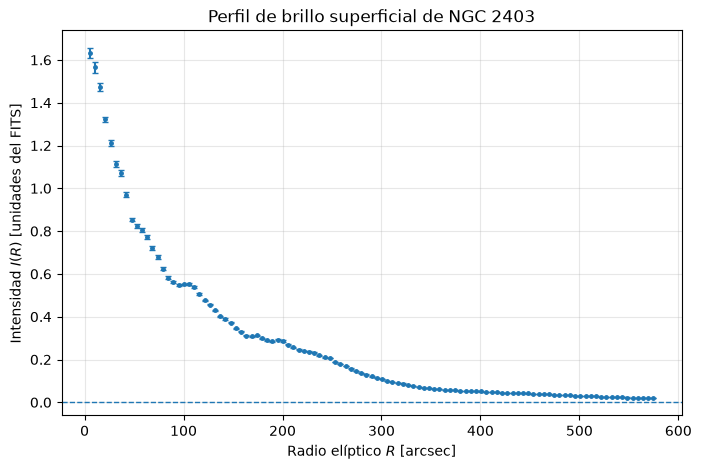

In [95]:
plt.figure(figsize=(8, 5))

plt.errorbar(
    perfil["R_arcsec"],
    perfil["I"],
    yerr=perfil["I_err"],
    fmt=".",
    markersize=5,
    capsize=2
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(r"Intensidad $I(R)$ [unidades del FITS]")
plt.title("Perfil de brillo superficial de NGC 2403")

plt.grid(alpha=0.3)
plt.show()

### Inspección del perfil en escala logarítmica

Para estudiar si alguna región de NGC 2403 presenta el comportamiento esperado para un disco exponencial, se consideran únicamente los puntos que cumplen $I(R)>0$ y cuyos valores de intensidad e incertidumbre son finitos.

Un disco estelar exponencial ideal puede describirse mediante

$$
I(R)=I_0\exp\left(-\frac{R}{h}\right),
$$

donde $I_0$ es la intensidad central extrapolada del disco y $h$ es su longitud de escala radial.

Por esta razón se representa inicialmente $I(R)$ utilizando una escala logarítmica en el eje vertical. Si una región del perfil sigue aproximadamente una ley exponencial, deberá aparecer visualmente cercana a una línea recta en este tipo de representación.

Esta gráfica se utiliza principalmente como herramienta de diagnóstico para identificar posibles intervalos radiales donde el disco pueda presentar un comportamiento aproximadamente exponencial.

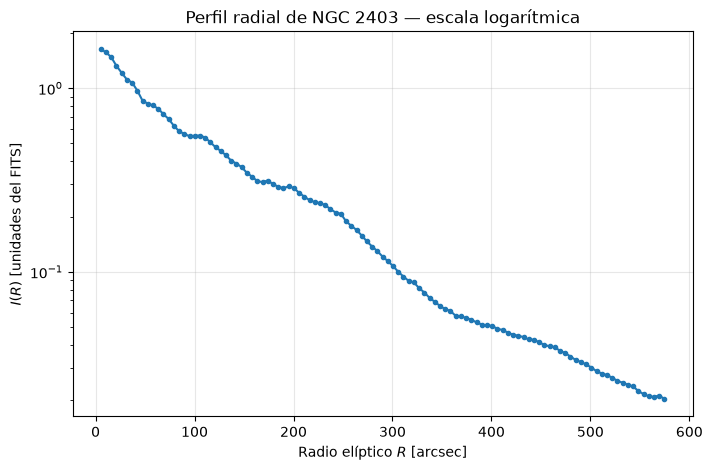

In [96]:
perfil_pos = perfil[
    (perfil["I"] > 0) &
    np.isfinite(perfil["I"]) &
    np.isfinite(perfil["I_err"])
].copy()

plt.figure(figsize=(8, 5))

plt.semilogy(
    perfil_pos["R_arcsec"],
    perfil_pos["I"],
    ".-"
)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(r"$I(R)$ [unidades del FITS]")
plt.title("Perfil radial de NGC 2403 — escala logarítmica")

plt.grid(alpha=0.3)
plt.show()

### Linealización del perfil exponencial

Para cuantificar el comportamiento exponencial se transforma explícitamente la intensidad utilizando el logaritmo natural.

Partiendo de

$$
I(R)=I_0\exp\left(-\frac{R}{h}\right),
$$

al aplicar logaritmo natural se obtiene

$$
\ln I(R)
=
\ln I_0
-
\frac{R}{h}.
$$

Esta expresión tiene la forma de una recta,

$$
\ln I(R)=A+mR,
$$

donde

$$
A=\ln I_0
$$

y

$$
m=-\frac{1}{h}.
$$

Por lo tanto, una región del disco que siga una distribución exponencial deberá mostrar un comportamiento aproximadamente lineal en la gráfica de $\ln I$ frente a $R$.

Además, mediante propagación de incertidumbres, para errores pequeños se tiene aproximadamente

$$
\sigma_{\ln I}
=
\left|
\frac{d\ln I}{dI}
\right|\sigma_I
=
\frac{\sigma_I}{I}.
$$

Por esta razón las barras de error del perfil logarítmico se calculan como

$$
\frac{I_{\rm err}}{I}.
$$

Esta representación permitirá posteriormente estimar la longitud de escala $h$ a partir de la pendiente de un ajuste lineal.

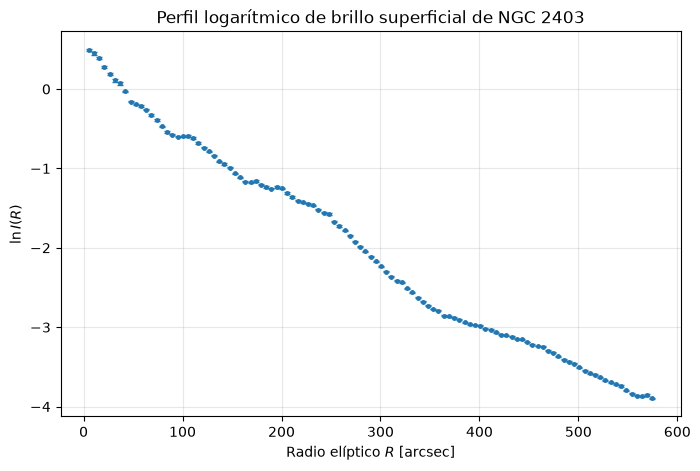

In [98]:
perfil_pos["lnI"] = np.log(perfil_pos["I"])

plt.figure(figsize=(8, 5))

plt.errorbar(
    perfil_pos["R_arcsec"],
    perfil_pos["lnI"],
    yerr=perfil_pos["I_err"] / perfil_pos["I"],
    fmt=".",
    markersize=5,
    capsize=2
)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(r"$\ln I(R)$")
plt.title("Perfil logarítmico de brillo superficial de NGC 2403")

plt.grid(alpha=0.3)
plt.show()

### Variación radial de la pendiente del perfil

Antes de seleccionar una región concreta para el ajuste exponencial se examina cómo cambia localmente la pendiente del perfil logarítmico.

Se calcula numéricamente $\frac{d\ln I}{dR}$ mediante diferencias finitas entre los puntos consecutivos del perfil. Para un disco perfectamente exponencial,

$$
\ln I(R)
=
\ln I_0-\frac{R}{h},
$$

por lo que su pendiente debería ser aproximadamente constante:

$$
\frac{d\ln I}{dR}
=
-\frac{1}{h}.
$$

En consecuencia, una región donde la pendiente local fluctúe alrededor de un valor aproximadamente constante constituye una candidata natural para ser descrita mediante una ley exponencial.

Las variaciones observadas en esta gráfica indican que el perfil completo de NGC 2403 no puede representarse adecuadamente mediante una única exponencial en todos los radios. Por ello, el siguiente paso consiste en comparar diferentes intervalos radiales y determinar en cuáles de ellos la relación entre $\ln I$ y $R$ es aproximadamente lineal.

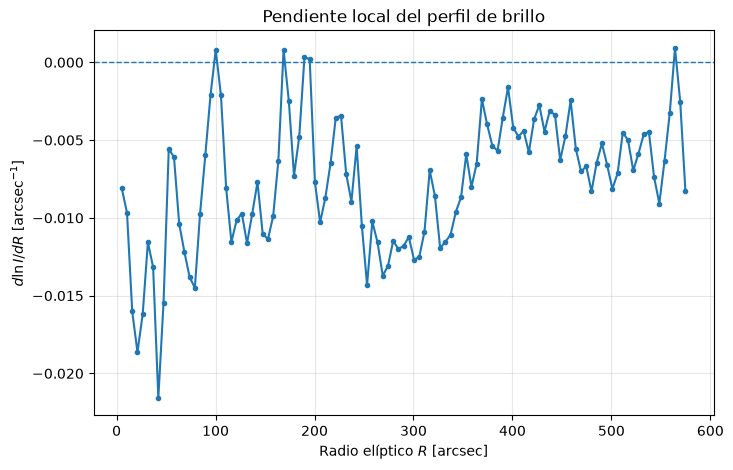

In [99]:
R = perfil_pos["R_arcsec"].to_numpy()
lnI = perfil_pos["lnI"].to_numpy()

pendiente_local = np.gradient(lnI, R)

plt.figure(figsize=(8, 5))

plt.plot(
    R,
    pendiente_local,
    ".-"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(r"$d\ln I/dR$ [arcsec$^{-1}$]")
plt.title("Pendiente local del perfil de brillo")

plt.grid(alpha=0.3)
plt.show()

### Evaluación de diferentes intervalos radiales

Para identificar cuantitativamente las regiones que pueden describirse mediante una ley exponencial se realizan ajustes lineales de $\ln I(R)=A+mR$ sobre diferentes intervalos radiales. Para cada intervalo se obtiene la pendiente $m$, el intercepto $A$ y el coeficiente de determinación $R^2$.

A partir de la pendiente se calcula directamente la longitud de escala exponencial:

$$
\boxed{
h=-\frac{1}{m}
}.
$$

Un valor de $R^2$ cercano a la unidad indica que, dentro del intervalo considerado, los puntos presentan un comportamiento aproximadamente lineal en el espacio $(R,\ln I)$ y, por tanto, son compatibles con una distribución aproximadamente exponencial.

Se comparan los siguientes intervalos:

$$
100-230,\qquad
130-240,\qquad
260-340,
$$

$$
380-540,\qquad
400-540
\quad {\rm arcsec}.
$$

Los ajustes producen distintas pendientes y longitudes de escala, lo que confirma que la estructura radial de NGC 2403 no queda descrita por una única exponencial sobre todo el rango observado.

Esta comparación permite distinguir diferentes regímenes del perfil antes de adoptar una región concreta para caracterizar el disco.

In [101]:
from scipy.stats import linregress

def ajustar_intervalo_disco(perfil, rmin, rmax):
    
    zona = perfil[
        (perfil["R_arcsec"] >= rmin) &
        (perfil["R_arcsec"] <= rmax) &
        (perfil["I"] > 0)
    ].copy()

    R = zona["R_arcsec"].to_numpy()
    lnI = np.log(zona["I"].to_numpy())

    ajuste = linregress(R, lnI)

    m = ajuste.slope
    A = ajuste.intercept
    r2 = ajuste.rvalue**2

    # Escala radial exponencial
    h = -1 / m

    return {
        "rmin": rmin,
        "rmax": rmax,
        "m": m,
        "A": A,
        "h_arcsec": h,
        "R2": r2
    }

In [102]:
intervalos = [
    (100, 230),
    (130, 240),
    (260, 340),
    (380, 540),
    (400, 540)
]

resultados = []

for rmin, rmax in intervalos:
    resultados.append(
        ajustar_intervalo_disco(
            perfil,
            rmin,
            rmax
        )
    )

tabla_ajustes = pd.DataFrame(resultados)

tabla_ajustes

,rmin,rmax,m,A,h_arcsec,R2
0,100,230,-0.006889,0.066220,145.156571,0.963442
1,130,240,-0.005683,-0.163693,175.958090,0.965386
2,260,340,-0.011326,1.184416,88.292996,0.996534
3,380,540,-0.005249,-0.867419,190.510809,0.986655
4,400,540,-0.005469,-0.759656,182.856744,0.989066


### Ajuste inicial de una componente exponencial externa

A partir de la comparación entre distintos intervalos radiales se selecciona inicialmente la región comprendida entre $380 \leq R \leq 540\ {\rm arcsec}$ como una zona representativa del comportamiento exponencial del disco externo.

En este intervalo se realiza un ajuste lineal de la forma $\ln I(R)=A+mR$. El ajuste proporciona

$$
m=-0.005249\ {\rm arcsec^{-1}},
$$

$$
A=-0.867419,
$$

y

$$
R^2=0.98666.
$$

Como para un disco exponencial

$$
m=-\frac{1}{h},
$$

la longitud de escala correspondiente es

$$
h=-\frac{1}{m},
$$

de donde se obtiene

$$
\boxed{
h_{\rm ext}\approx190.51\ {\rm arcsec}
}.
$$

El valor elevado de $R^2$ indica que, dentro de este intervalo, el perfil logarítmico presenta una relación aproximadamente lineal con el radio.

Sin embargo, este ajuste se interpreta inicialmente como una caracterización de la región externa seleccionada y no necesariamente como una única descripción del disco completo. Las diferencias encontradas anteriormente entre las pendientes de distintos intervalos sugieren que la estructura radial de NGC 2403 presenta más de un régimen.

In [103]:
# Región adoptada inicialmente como disco exponencial externo
zona_disco = perfil[
    (perfil["R_arcsec"] >= 380) &
    (perfil["R_arcsec"] <= 540) &
    (perfil["I"] > 0)
].copy()

R_disco = zona_disco["R_arcsec"].to_numpy()
lnI_disco = np.log(zona_disco["I"].to_numpy())

ajuste_disco = linregress(
    R_disco,
    lnI_disco
)

m_disco = ajuste_disco.slope
A_disco = ajuste_disco.intercept
R2_disco = ajuste_disco.rvalue**2

h_arcsec = -1 / m_disco

print(f"Pendiente m = {m_disco:.6f} arcsec^-1")
print(f"Intercepto A = {A_disco:.6f}")
print(f"R² = {R2_disco:.5f}")
print(f"Escala radial h = {h_arcsec:.2f} arcsec")

Pendiente m = -0.005249 arcsec^-1
Intercepto A = -0.867419
R² = 0.98666
Escala radial h = 190.51 arcsec


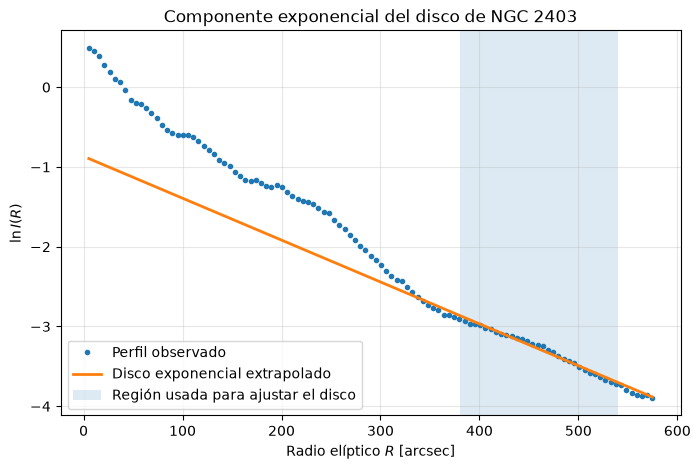

In [104]:
R_modelo = np.linspace(
    perfil_pos["R_arcsec"].min(),
    perfil_pos["R_arcsec"].max(),
    500
)

lnI_modelo_disco = A_disco + m_disco * R_modelo

plt.figure(figsize=(8, 5))

plt.plot(
    perfil_pos["R_arcsec"],
    perfil_pos["lnI"],
    ".",
    label="Perfil observado"
)

plt.plot(
    R_modelo,
    lnI_modelo_disco,
    linewidth=2,
    label="Disco exponencial extrapolado"
)

plt.axvspan(
    380,
    540,
    alpha=0.15,
    label="Región usada para ajustar el disco"
)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(r"$\ln I(R)$")
plt.title("Componente exponencial del disco de NGC 2403")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Comparación del perfil observado con la extrapolación exponencial

Una vez obtenidos los parámetros del ajuste externo, la relación lineal en el espacio logarítmico se transforma nuevamente a intensidad:

$$
I_{\rm disco}(R)
=
\exp(A+mR).
$$

Esta expresión representa la intensidad que tendría la galaxia si la componente exponencial determinada en la región externa continuara con la misma pendiente hacia otros radios.

Para evaluar las desviaciones respecto a este modelo se calcula

$$
I_{\rm exceso}(R)
=
I_{\rm obs}(R)-I_{\rm disco}(R).
$$

La interpretación del signo es directa:

$$
I_{\rm exceso}>0
$$

indica que el perfil observado contiene más luz que la predicha por la extrapolación exponencial, mientras que

$$
I_{\rm exceso}<0
$$

indica que la intensidad observada se encuentra por debajo del modelo.

Esta comparación permite visualizar qué regiones del perfil no están adecuadamente descritas por la exponencial externa y proporciona una primera evidencia de que el perfil radial contiene diferentes componentes o cambios estructurales.

En particular, un exceso de luz hacia las regiones internas puede sugerir la presencia de una componente central adicional, aunque esta interpretación debe comprobarse utilizando una representación adecuada del disco principal antes de asociar directamente dicho exceso con el bulbo.

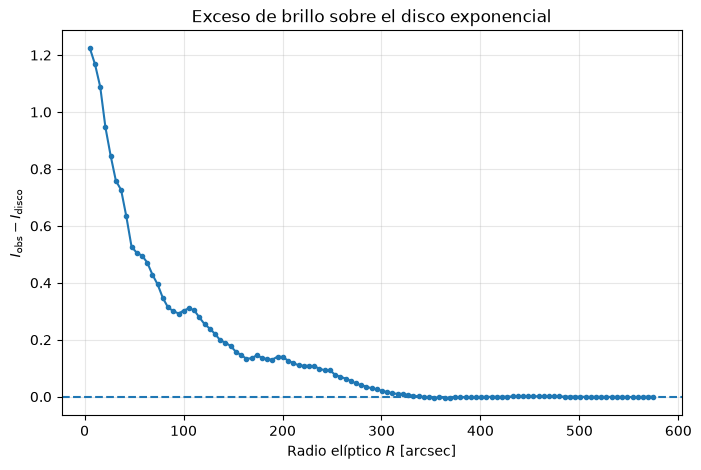

In [105]:
perfil_pos["I_disco"] = np.exp(
    A_disco +
    m_disco * perfil_pos["R_arcsec"]
)

perfil_pos["I_exceso"] = (
    perfil_pos["I"] -
    perfil_pos["I_disco"]
)

plt.figure(figsize=(8, 5))

plt.plot(
    perfil_pos["R_arcsec"],
    perfil_pos["I_exceso"],
    ".-"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(r"$I_{\rm obs}-I_{\rm disco}$")
plt.title("Exceso de brillo sobre el disco exponencial")

plt.grid(alpha=0.3)
plt.show()

### Ajuste de la componente principal del disco

La inspección del perfil muestra que la exponencial ajustada únicamente en la región más externa no representa necesariamente la estructura dominante del disco a radios intermedios.

Por esta razón se adopta el intervalo

$$
100 \leq R \leq 230\ {\rm arcsec}
$$

como una región representativa del **disco principal** y se realiza nuevamente un ajuste lineal de

$$
\ln I(R)=A+mR.
$$

Para este intervalo se obtiene

$$
m=-0.006889\ {\rm arcsec^{-1}},
$$

$$
A=0.066220,
$$

y

$$
R^2=0.96344.
$$

La longitud de escala exponencial correspondiente es

$$
h_{\rm disco}
=
-\frac{1}{m},
$$

por lo que

$$
\boxed{
h_{\rm disco}\approx145.16\ {\rm arcsec}
}.
$$

Este valor se utiliza a continuación para construir una representación de la componente principal del disco y estudiar el exceso de luz presente en la región central.

La diferencia entre esta escala y la obtenida previamente para la región externa,

$$
h_{\rm disco}\approx145''
\qquad \text{frente a} \qquad
h_{\rm ext}\approx191'',
$$

refuerza la conclusión de que el perfil de NGC 2403 no presenta una única pendiente exponencial constante en todo el rango radial analizado.

In [106]:
# Región adoptada para representar el disco principal
zona_disco_principal = perfil[
    (perfil["R_arcsec"] >= 100) &
    (perfil["R_arcsec"] <= 230) &
    (perfil["I"] > 0)
].copy()

R_disco_principal = zona_disco_principal["R_arcsec"].to_numpy()
lnI_disco_principal = np.log(
    zona_disco_principal["I"].to_numpy()
)

ajuste_principal = linregress(
    R_disco_principal,
    lnI_disco_principal
)

m_principal = ajuste_principal.slope
A_principal = ajuste_principal.intercept
R2_principal = ajuste_principal.rvalue**2

h_principal = -1 / m_principal

print(f"m = {m_principal:.6f} arcsec^-1")
print(f"A = {A_principal:.6f}")
print(f"R² = {R2_principal:.5f}")
print(f"h = {h_principal:.2f} arcsec")

m = -0.006889 arcsec^-1
A = 0.066220
R² = 0.96344
h = 145.16 arcsec


### Extrapolación del disco principal hacia la región central

Una vez determinado el ajuste exponencial del disco principal en el intervalo

$$
100 \leq R \leq 230\ {\rm arcsec},
$$

se extrapola dicho modelo hacia radios menores para comparar su comportamiento con el perfil observado en la región central.

El modelo adoptado es

$$
\ln I_{\rm disco}(R)
=
A_{\rm principal}
+
m_{\rm principal}R,
$$

con

$$
A_{\rm principal}=0.066220
$$

y

$$
m_{\rm principal}
=
-0.006889\ {\rm arcsec^{-1}}.
$$

La extrapolación hacia $R\rightarrow0$ representa el brillo que tendría el disco si mantuviera la misma ley exponencial observada en la región intermedia.

Al comparar este modelo con el perfil observado puede identificarse visualmente si existe un exceso de luz en las regiones centrales. Dicho exceso constituye una primera indicación de una componente adicional al disco, aunque todavía no se interpreta automáticamente como un bulbo independiente.

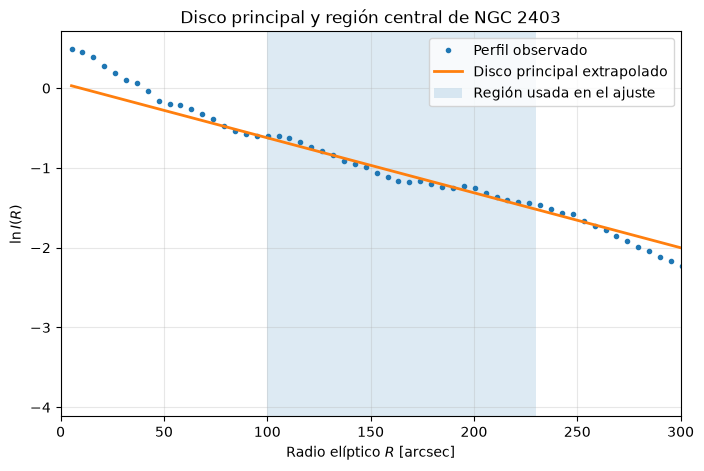

In [107]:
R_modelo = np.linspace(
    perfil_pos["R_arcsec"].min(),
    300,
    400
)

lnI_modelo_principal = (
    A_principal +
    m_principal * R_modelo
)

plt.figure(figsize=(8, 5))

plt.plot(
    perfil_pos["R_arcsec"],
    perfil_pos["lnI"],
    ".",
    label="Perfil observado"
)

plt.plot(
    R_modelo,
    lnI_modelo_principal,
    linewidth=2,
    label="Disco principal extrapolado"
)

plt.axvspan(
    100,
    230,
    alpha=0.15,
    label="Región usada en el ajuste"
)

plt.xlim(0, 300)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(r"$\ln I(R)$")
plt.title("Disco principal y región central de NGC 2403")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Estimación del exceso central de intensidad

Para cuantificar la diferencia entre el perfil observado y el disco exponencial principal, el modelo logarítmico se transforma nuevamente a intensidad:

$$
I_{\rm disco}(R)
=
\exp
\left(
A_{\rm principal}
+
m_{\rm principal}R
\right).
$$

definimos el exceso central como

$$
I_{\rm central}(R)
=
I_{\rm obs}(R)
-
I_{\rm disco}(R).
$$

Por tanto,

$$
I_{\rm central}>0
$$

indica que la galaxia presenta más intensidad que la predicha por la extrapolación del disco, mientras que valores cercanos a cero indican que el disco exponencial reproduce aproximadamente el perfil observado.

La representación de

$$
I_{\rm obs}-I_{\rm disco}
$$

en los primeros $250''$ permite localizar radialmente dónde comienza a ser importante esta emisión adicional.

In [108]:
perfil_pos["I_disco_principal"] = np.exp(
    A_principal +
    m_principal * perfil_pos["R_arcsec"]
)

perfil_pos["exceso_central"] = (
    perfil_pos["I"] -
    perfil_pos["I_disco_principal"]
)

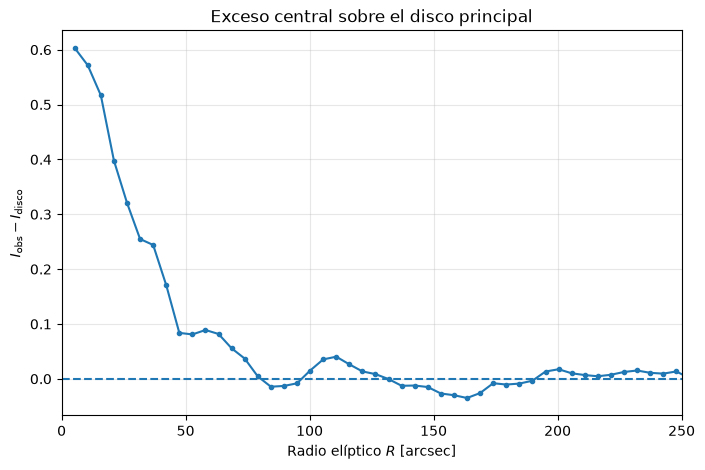

In [109]:
plt.figure(figsize=(8, 5))

plt.plot(
    perfil_pos["R_arcsec"],
    perfil_pos["exceso_central"],
    ".-"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlim(0, 250)

plt.xlabel(r"Radio elíptico $R$ [arcsec]")
plt.ylabel(
    r"$I_{\rm obs}-I_{\rm disco}$"
)

plt.title(
    "Exceso central sobre el disco principal"
)

plt.grid(alpha=0.3)
plt.show()

### Región de transición entre la componente central y el disco

La extrapolación del disco exponencial principal hacia radios pequeños permite
definir el exceso de intensidad

$$
\Delta I(R)
=
I_{\rm obs}(R)-I_{\rm disco}(R).
$$

En la región central se observa un exceso positivo de brillo respecto al disco.
Este exceso disminuye progresivamente con el radio y se hace aproximadamente
nulo alrededor de

$$
R \sim 70-80''.
$$

Por tanto, se adopta de manera aproximada

$$
\boxed{
R_{\rm trans}\approx75\pm10''
}
$$

como la región de transición entre la componente central y el disco principal.

Este radio no debe interpretarse estrictamente como una igualdad
$I_{\rm bulbo}=I_{\rm disco}$, sino como el punto donde el perfil observado
pasa a estar adecuadamente descrito por la componente exponencial del disco.

La ausencia de una transición marcada entre dos componentes dominantes es
consistente con el carácter fuertemente dominado por el disco de NGC 2403 y
con la falta de un bulbo clásico prominente.

## Estimación de la clasificación de Hubble

A partir de las propiedades fotométricas obtenidas es posible realizar una
estimación de la posición de NGC 2403 dentro de la secuencia morfológica de
Hubble.

La imagen muestra claramente una estructura de disco con brazos espirales, por
lo que NGC 2403 corresponde a una galaxia espiral y no a una galaxia elíptica
o lenticular.

El perfil radial muestra además que una región amplia del disco puede
describirse mediante un perfil exponencial,

$$
I(R)=I_0e^{-R/h},
$$

con una longitud de escala

$$
h_{\rm disco}\simeq145.16''.
$$

Al extrapolar este modelo hacia radios pequeños se encuentra un exceso central
de intensidad,

$$
\Delta I(R)
=
I_{\rm obs}(R)-I_{\rm disco}(R),
$$

pero dicho exceso disminuye rápidamente con el radio y se hace aproximadamente
nulo alrededor de

$$
R\sim70-80''.
$$

Se adoptó por tanto una región de transición aproximada de

$$
\boxed{
R_{\rm trans}\approx75\pm10''
}.
$$

Este comportamiento indica que la componente central se encuentra confinada a
la región interna y que, fuera de ella, la luminosidad está fuertemente
dominada por el disco exponencial. No se observa fotométricamente una
protuberancia central grande y dominante característica de las espirales
tempranas.

Dentro de la secuencia de Hubble:

- las galaxias **Sa** presentan una componente central prominente y una fuerte
  concentración de luz;
- las **Sb** representan un caso intermedio;
- las **Sc** presentan una mayor dominancia del disco y una componente central
  relativamente pequeña.

Por tanto, las propiedades fotométricas medidas favorecen una clasificación
hacia el extremo tardío de la secuencia espiral. Con la información disponible,
NGC 2403 puede describirse aproximadamente como una galaxia de tipo

$$
\boxed{\mathrm{SBc-Sc}},
$$

adoptándose **Sc** como clasificación provisional para los cálculos posteriores.

Esta clasificación no debe considerarse definitiva únicamente a partir del
perfil fotométrico. Un segundo criterio importante dentro de la clasificación
de galaxias espirales es el grado de apertura de los brazos, que puede
cuantificarse mediante el *pitch angle*.

Se intentó deproyectar la galaxia a una vista aproximadamente *face-on* para
medir dicho ángulo. Sin embargo, el resultado mostró una dependencia
significativa con la geometría utilizada para la deproyección y con la
selección de los brazos, por lo que no se obtuvo una medida de *pitch angle*
suficientemente robusta para utilizarla como criterio independiente de
clasificación.

Por esta razón, la clasificación adoptada se basa principalmente en la
dominancia fotométrica del disco y en la baja importancia relativa de la
componente central.

Finalmente, tampoco se realizó una identificación cuantitativa suficientemente
robusta de una barra central. Por ello no se asigna de forma definitiva la
familia no barrada o barrada ($S$ frente a $SB$).

## Distancia a la que se encuentra la galaxia

En una galaxia espiral, la velocidad característica de la región aproximadamente plana de la curva de rotación puede relacionarse con la luminosidad de la galaxia mediante la **relación de Tully--Fisher**.



In [133]:
ruta_rot = "datos/NGC2403_Rot_Curve.dat"

rot = np.loadtxt(ruta_rot, comments="#")

R_rot = rot[:, 0]   # radio [kpc]
V_rot = rot[:, 1]   # velocidad [km/s]

print("Número de puntos:", len(R_rot))
print(f"R mínimo = {R_rot.min():.2f} kpc")
print(f"R máximo = {R_rot.max():.2f} kpc")
print(f"V mínima = {V_rot.min():.2f} km/s")
print(f"V máxima = {V_rot.max():.2f} km/s")

Número de puntos: 395
R mínimo = 0.00 kpc
R máximo = 19.70 kpc
V mínima = 47.90 km/s
V máxima = 137.50 km/s


V_max = 137.50 km/s
Se alcanza en R = 13.80 kpc


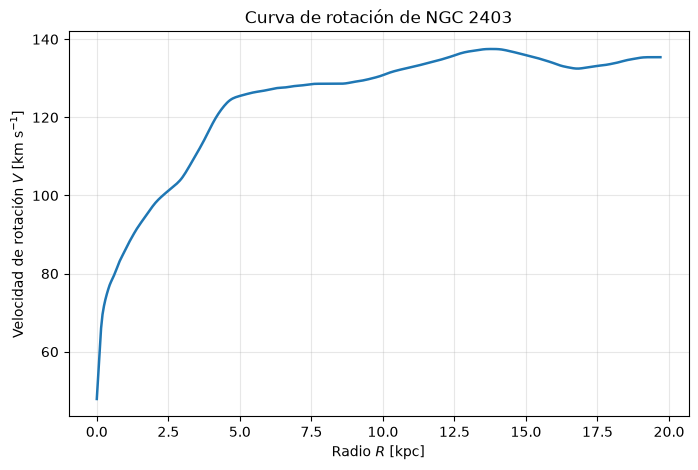

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(R_rot, V_rot, "-", linewidth=1.8)
plt.xlabel(r"Radio $R$ [kpc]")
plt.ylabel(r"Velocidad de rotación $V$ [km s$^{-1}$]")
plt.title("Curva de rotación de NGC 2403")
plt.grid(alpha=0.3)
plt.show()

La curva muestra inicialmente un aumento rápido de la velocidad de rotación con el radio. Posteriormente, el crecimiento se hace mucho más lento y la curva alcanza una región aproximadamente plana.

Este comportamiento es característico de las curvas de rotación de galaxias espirales: después de la región interna, la velocidad orbital no disminuye de forma kepleriana, sino que permanece aproximadamente constante a grandes radios.

Para la aplicación de la relación de Tully--Fisher interesa precisamente esta velocidad característica de rotación.

In [138]:
# Velocidad máxima
i_max = np.argmax(V_rot)

V_max = V_rot[i_max]
R_Vmax = R_rot[i_max]

print(f"V_max = {V_max:.2f} km/s")
print(f"Se alcanza en R = {R_Vmax:.2f} kpc")


# Región aproximadamente plana
mascara_flat = R_rot >= 10.0

R_flat = R_rot[mascara_flat]
V_flat_datos = V_rot[mascara_flat]

V_flat = np.median(V_flat_datos)
sigma_flat = np.std(V_flat_datos, ddof=1)

print()
print(f"V_flat = {V_flat:.2f} km/s")
print(f"Dispersión en la región plana = {sigma_flat:.2f} km/s")

V_max = 137.50 km/s
Se alcanza en R = 13.80 kpc

V_flat = 134.61 km/s
Dispersión en la región plana = 1.74 km/s


In [145]:
M_B = -11.0 * np.log10(V_max) + 3.31

print(f"Magnitud absoluta estimada M_B = {M_B:.2f}")

Magnitud absoluta estimada M_B = -20.21


### Magnitud absoluta mediante la relación de Tully--Fisher

La relación de Tully--Fisher establece una correlación entre la luminosidad de una galaxia espiral y su velocidad máxima de rotación.

Dado que el análisis morfológico realizado anteriormente apunta provisionalmente hacia una galaxia espiral de tipo Sc, se utiliza la calibración

$$
M_B
=
-11.0\log_{10}(V_{\max})
+
3.31,
$$

donde $V_{\max}$ se expresa en ${\rm km\,s^{-1}}$.

Utilizando

$$
V_{\max}=137.50\ {\rm km\,s^{-1}},
$$

se obtiene

$$
M_B
=
-11.0\log_{10}(137.50)+3.31,
$$

y por tanto

$$
\boxed{
M_B\simeq-20.21
}.
$$

Este valor representa una estimación de la magnitud absoluta de NGC 2403 en la banda $B$ a partir de su dinámica rotacional.

### Módulo de distancia

Para convertir la magnitud absoluta estimada mediante Tully--Fisher en una distancia, se utiliza el módulo de distancia.

La magnitud aparente reportada para NGC 2403 en banda $B$ es

$$
m_B = 8.93,
$$

y se adopta una extinción galáctica en dicha banda de

$$
A_B = 0.17\ {\rm mag}.
$$

Por tanto, la magnitud aparente corregida por extinción es

$$
m_{B,0}=m_B-A_B,
$$

de modo que

$$
m_{B,0}=8.93-0.17=8.76.
$$

El módulo de distancia se define como

$$
\mu=m_{B,0}-M_B.
$$

Utilizando

$$
M_B\simeq-20.21,
$$

se obtiene

$$
\mu=8.76-(-20.21)=28.97.
$$

La relación entre módulo de distancia y distancia es

$$
\mu
=
5\log_{10}\left(\frac{D}{10\ {\rm pc}}\right).
$$

Despejando,

$$
D({\rm pc})
=
10^{(\mu+5)/5},
$$

o, equivalentemente,

$$
D({\rm Mpc})
=
10^{(\mu-25)/5}.
$$

Por tanto,

$$
D
=
10^{(28.97-25)/5},
$$

y finalmente

$$
\boxed{
D\simeq6.22\ {\rm Mpc}
}.
$$

### Análisis del resultado

La aplicación directa de la relación de Tully--Fisher adoptada para galaxias de tipo Sc proporciona una distancia aproximada de

$$
\boxed{
D_{\rm TF}\simeq6.2\ {\rm Mpc}
}.
$$

Este valor debe interpretarse como una **estimación indirecta de distancia**, ya que depende de la calibración adoptada para la relación de Tully--Fisher, de la clasificación morfológica utilizada y de la velocidad característica seleccionada para la galaxia.


La distancia obtenida es mayor que valores geométricos reportados para NGC 2403, del orden de unos pocos Mpc. Esta discrepancia no se debe a un error algebraico en el módulo de distancia, sino a las limitaciones de la calibración de Tully--Fisher utilizada y a su dispersión intrínseca.

Por esta razón, el valor

$$
D_{\rm TF}\simeq6.2\ {\rm Mpc}
$$

debe entenderse como la distancia estimada específicamente a partir del procedimiento de Tully--Fisher empleado en este análisis, y no como una determinación geométrica precisa de la distancia real de NGC 2403.

### ¿Qué sería necesario para obtener una distancia de $\sim 3$ Mpc?

La estimación realizada con la calibración de Tully--Fisher adoptada proporciona

$$
D_{\rm TF}\simeq 6.2\ {\rm Mpc}.
$$

Sin embargo, para NGC 2403 se reportan también distancias independientes del orden de

$$
D\sim2.9-3.5\ {\rm Mpc}.
$$

La diferencia no puede corregirse únicamente mediante la extinción galáctica, ya que

$$
A_B=0.17\ {\rm mag}
$$

solo modifica ligeramente el módulo de distancia.

Para comprobar qué magnitud absoluta sería necesaria para obtener una distancia de
$3.2-3.5$ Mpc, se puede invertir el módulo de distancia.

Con

$$
m_{B,0}=m_B-A_B=8.76,
$$

una distancia de $3.2-3.5$ Mpc corresponde aproximadamente a

$$
\mu\simeq27.31-27.72,
$$

por lo que sería necesario

$$
M_B=m_{B,0}-\mu
\simeq -18.55\ \text{a}\ -18.96.
$$

Este intervalo es considerablemente menos luminoso que el valor

$$
M_B\simeq-20.21
$$

obtenido con la calibración de Tully--Fisher utilizada.

Si se mantuviera exactamente la relación

$$
M_B=-11\log_{10}(V_{\max})+3.31,
$$

una magnitud absoluta de $M_B\simeq-18.8$ requeriría una velocidad característica de solo

$$
V_{\max}\sim102-106\ {\rm km\,s^{-1}},
$$

en lugar de los $137.5\ {\rm km\,s^{-1}}$ medidos en la curva de rotación.

Por tanto, para obtener una distancia cercana a $3.2-3.5$ Mpc sería necesario utilizar
una **calibración diferente de Tully--Fisher**, apropiada para el observable empleado,
o recurrir a un **indicador de distancia independiente**.

En particular, si se utilizara un ancho de línea HI, $W$, este debería introducirse en una
relación de Tully--Fisher calibrada específicamente en términos de $W$, y no sustituirse
directamente en una relación escrita para $V_{\max}$.

Por esta razón, el valor obtenido aquí debe interpretarse como el resultado de la calibración
específica adoptada, y no como una determinación geométrica de alta precisión.

In [ ]:
# Comprobación inversa:
# ¿qué M_B y qué V_max serían necesarios para obtener
# una distancia entre 3.2 y 3.5 Mpc?

m_B = 8.93
A_B = 0.17

# Magnitud aparente corregida por extinción
m_B0 = m_B - A_B

for D_Mpc in [2.9, 3.0, 3.2, 3.3, 3.5]:

    # Módulo de distancia
    mu = 5 * np.log10(D_Mpc) + 25

    # Magnitud absoluta necesaria
    M_B_necesaria = m_B0 - mu

    # Invertimos la relación de Tully-Fisher:
    #
    # M_B = -11 log10(Vmax) + 3.31
    #
    # log10(Vmax) = (3.31 - M_B)/11

    V_necesaria = 10**((3.31 - M_B_necesaria) / 11)

    print(
        f"D = {D_Mpc:.1f} Mpc  ->  "
        f"mu = {mu:.2f}, "
        f"M_B = {M_B_necesaria:.2f}, "
        f"Vmax requerida = {V_necesaria:.1f} km/s"
    )

D = 2.9 Mpc  ->  mu = 27.31, M_B = -18.55, Vmax requerida = 97.2 km/s
D = 3.0 Mpc  ->  mu = 27.39, M_B = -18.63, Vmax requerida = 98.7 km/s
D = 3.2 Mpc  ->  mu = 27.53, M_B = -18.77, Vmax requerida = 101.6 km/s
D = 3.3 Mpc  ->  mu = 27.59, M_B = -18.83, Vmax requerida = 103.0 km/s
D = 3.5 Mpc  ->  mu = 27.72, M_B = -18.96, Vmax requerida = 105.8 km/s


### Escala radial física del disco

Del ajuste exponencial realizado sobre la región principal del disco se obtuvo una longitud de escala angular

$$
h_{\rm disco}=145.16''.
$$

Para convertir esta escala angular en una distancia física se utiliza la aproximación de ángulo pequeño,

$$
h_{\rm kpc}=D\,\theta,
$$

donde $D$ es la distancia a la galaxia y $\theta$ debe expresarse en radianes.

Como

$$
1\ {\rm rad}=206265'',
$$

entonces

$$
\theta=
\frac{h_{\rm disco}}{206265}.
$$

Utilizando la distancia estimada mediante Tully--Fisher,

$$
D_{\rm TF}\simeq6.22\ {\rm Mpc}
=
6220\ {\rm kpc},
$$

se obtiene

$$
h_{\rm disco}
=
6220
\left(
\frac{145.16}{206265}
\right)
{\rm kpc}.
$$

Por tanto,

$$
\boxed{
h_{\rm disco}\simeq4.38\ {\rm kpc}
}.
$$

Este valor representa la distancia radial característica sobre la cual la intensidad del disco exponencial disminuye por un factor $e$:

$$
I(R)=I_0 e^{-R/h}.
$$

Es decir, al aumentar el radio en una longitud de escala $h_{\rm disco}$, la intensidad superficial del disco disminuye hasta aproximadamente

$$
\frac{1}{e}\simeq0.368
$$

de su valor anterior.

In [148]:
# Escala radial angular obtenida del ajuste exponencial
h_arcsec = h_principal

# Distancia estimada mediante Tully-Fisher
D_Mpc = 6.22
D_kpc = D_Mpc * 1000

# Conversión arcsec -> radianes y escala física
h_kpc = D_kpc * h_arcsec / 206265

print(f"h = {h_arcsec:.2f} arcsec")
print(f"D = {D_Mpc:.2f} Mpc")
print(f"h = {h_kpc:.2f} kpc")

h = 145.16 arcsec
D = 6.22 Mpc
h = 4.38 kpc


### Clasificador morfológico para galaxias elípticas

Para las galaxias elípticas, la clasificación de Hubble depende principalmente
de la elipticidad aparente de sus isofotas.

La elipticidad se define como

$$
\epsilon = 1-\frac{b}{a},
$$

donde $a$ y $b$ son los semiejes mayor y menor de una isofota.

La clasificación morfológica se expresa como

$$
E_n,
$$

donde aproximadamente

$$
n=10\epsilon.
$$


Como las isofotas individuales pueden estar afectadas por ruido, estrellas de
campo o la PSF en la región central, no se utilizará una única elipse para
clasificar la galaxia. En su lugar, se ajustará una familia de isofotas y se
adoptará como elipticidad representativa la mediana de una región externa
estable del perfil $\epsilon(R)$.

El procedimiento será:

1. cargar la imagen FITS;
2. estimar y sustraer el fondo del cielo;
3. determinar aproximadamente el centro fotométrico;
4. ajustar isofotas elípticas;
5. estudiar $\epsilon$ como función del radio;
6. obtener una elipticidad representativa;
7. calcular $n\simeq10\epsilon$ y asignar la clasificación $E_n$.

In [207]:
def preparar_imagen_eliptica(
    ruta_fits,
    borde=100,
    sigma_smooth=3
):

    # ---------------------------------------------
    # Abrir imagen FITS
    # ---------------------------------------------
    with fits.open(ruta_fits) as hdul:
        imagen = hdul[0].data.astype(float)

    # ---------------------------------------------
    # Estimación del cielo usando los bordes
    # ---------------------------------------------
    bordes = np.concatenate([
        imagen[:borde, :].ravel(),
        imagen[-borde:, :].ravel(),
        imagen[:, :borde].ravel(),
        imagen[:, -borde:].ravel()
    ])

    media_sky, mediana_sky, sigma_sky = sigma_clipped_stats(
        bordes,
        sigma=3,
        maxiters=5
    )

    # Restar cielo
    imagen_sky = imagen - mediana_sky

    # ---------------------------------------------
    # Suavizado para determinar geometría
    # ---------------------------------------------
    imagen_suave = gaussian_filter(
        imagen_sky,
        sigma=sigma_smooth
    )

    # ---------------------------------------------
    # Ruido de la imagen suavizada
    # ---------------------------------------------
    bordes_suaves = np.concatenate([
        imagen_suave[:borde, :].ravel(),
        imagen_suave[-borde:, :].ravel(),
        imagen_suave[:, :borde].ravel(),
        imagen_suave[:, -borde:].ravel()
    ])

    _, _, sigma_sky_suave = sigma_clipped_stats(
        bordes_suaves,
        sigma=3,
        maxiters=5
    )

    return (
        imagen,
        imagen_sky,
        imagen_suave,
        mediana_sky,
        sigma_sky,
        sigma_sky_suave
    )

In [208]:
def estimar_centro(
    imagen_suave,
    fraccion=0.5,
    percentil_max=99.5
):

    ny, nx = imagen_suave.shape

    xc0 = nx // 2
    yc0 = ny // 2

    dx = int(nx * fraccion / 2)
    dy = int(ny * fraccion / 2)

    x1 = xc0 - dx
    x2 = xc0 + dx
    y1 = yc0 - dy
    y2 = yc0 + dy

    recorte = imagen_suave[y1:y2, x1:x2].copy()

    # Eliminar NaN
    recorte[~np.isfinite(recorte)] = 0

    # No utilizar valores negativos
    recorte[recorte < 0] = 0

    # Evitar que uno o pocos píxeles brillantes
    # dominen el centroide
    limite = np.percentile(
        recorte[recorte > 0],
        percentil_max
    )

    recorte = np.clip(
        recorte,
        0,
        limite
    )

    yc_local, xc_local = centroid_com(
        recorte
    )

    xc = x1 + xc_local
    yc = y1 + yc_local

    return xc, yc

In [209]:
def estimar_geometria_inicial(
    imagen_suave,
    xc,
    yc,
    sigma_sky_suave,
    radio=50,
    snr_min=2
):

    y, x = np.indices(
        imagen_suave.shape
    )

    dx = x - xc
    dy = y - yc

    r = np.sqrt(
        dx**2 + dy**2
    )

    # ---------------------------------------------
    # Seleccionar región alrededor de la galaxia
    # ---------------------------------------------
    mascara = (
        np.isfinite(imagen_suave) &
        (r <= radio) &
        (imagen_suave > snr_min * sigma_sky_suave)
    )

    # Intensidad usada como peso
    peso = np.zeros_like(
        imagen_suave,
        dtype=float
    )

    peso[mascara] = imagen_suave[mascara]

    flujo = np.sum(peso)

    if flujo <= 0:
        raise ValueError(
            "No hay suficiente señal para estimar "
            "la geometría inicial."
        )

    # ---------------------------------------------
    # Momentos de segundo orden
    # ---------------------------------------------
    Mxx = np.sum(
        peso * dx**2
    ) / flujo

    Myy = np.sum(
        peso * dy**2
    ) / flujo

    Mxy = np.sum(
        peso * dx * dy
    ) / flujo

    matriz = np.array([
        [Mxx, Mxy],
        [Mxy, Myy]
    ])

    valores, vectores = np.linalg.eigh(
        matriz
    )

    # Mayor autovalor = eje mayor
    orden = np.argsort(
        valores
    )[::-1]

    valores = valores[orden]
    vectores = vectores[:, orden]

    lambda_a = valores[0]
    lambda_b = valores[1]

    # ---------------------------------------------
    # Relación de ejes
    # ---------------------------------------------
    q = np.sqrt(
        lambda_b / lambda_a
    )

    eps0 = 1 - q

    # Evitar valores numéricamente extremos
    eps0 = np.clip(
        eps0,
        0.01,
        0.80
    )

    # ---------------------------------------------
    # Ángulo del eje mayor
    # ---------------------------------------------
    vx = vectores[0, 0]
    vy = vectores[1, 0]

    pa0 = np.arctan2(
        vy,
        vx
    )

    # Una elipse es equivalente al rotarla 180 grados
    pa0 = pa0 % np.pi

    return eps0, pa0

In [230]:
imagen, imagen_sky, imagen_suave, sky, _, _ = preparar_imagen_eliptica(
    "datos/M87_SDSS9_g.fits"
)

xc, yc = estimar_centro(imagen_suave)

print(f"Centro estimado: ({xc:.2f}, {yc:.2f}) px")

Centro estimado: (899.30, 899.55) px


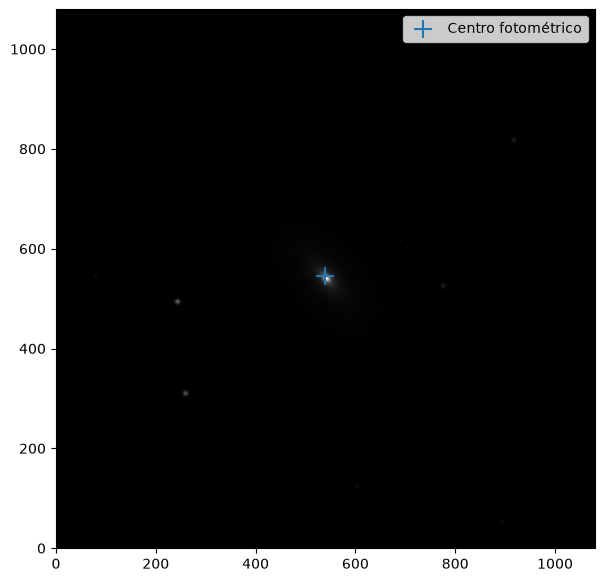

In [189]:
plt.figure(figsize=(7, 7))

plt.imshow(
    imagen_suave,
    origin="lower",
    cmap="gray"
)

plt.scatter(
    xc,
    yc,
    marker="+",
    s=150,
    label="Centro fotométrico"
)

plt.legend()
plt.show()

In [210]:
def ajustar_isofotas_eliptica(
    imagen_suave,
    xc,
    yc,
    eps0,
    pa0,
    sma0=30,
    minsma=5,
    maxsma=None
):

    ny, nx = imagen_suave.shape

    if maxsma is None:
        maxsma = 0.45 * min(nx, ny)

    # ---------------------------------------------
    # Geometría inicial
    # ---------------------------------------------
    geometria = EllipseGeometry(
        x0=xc,
        y0=yc,
        sma=sma0,
        eps=eps0,
        pa=pa0
    )

    ellipse = Ellipse(
        imagen_suave,
        geometry=geometria
    )

    # ---------------------------------------------
    # Ajuste
    # ---------------------------------------------
    isolist = ellipse.fit_image(
        sma0=sma0,
        minsma=minsma,
        maxsma=maxsma,
        step=0.1,

        sclip=3,
        n_clip=3,

        # El centro ya fue determinado
        fix_center=True,

        # Queremos medir estos parámetros
        fix_pa=False,
        fix_eps=False
    )

    return isolist

In [191]:
sma = np.array([iso.sma for iso in isolist])
eps = np.array([iso.eps for iso in isolist])
pa = np.array([iso.pa for iso in isolist])
intens = np.array([iso.intens for iso in isolist])

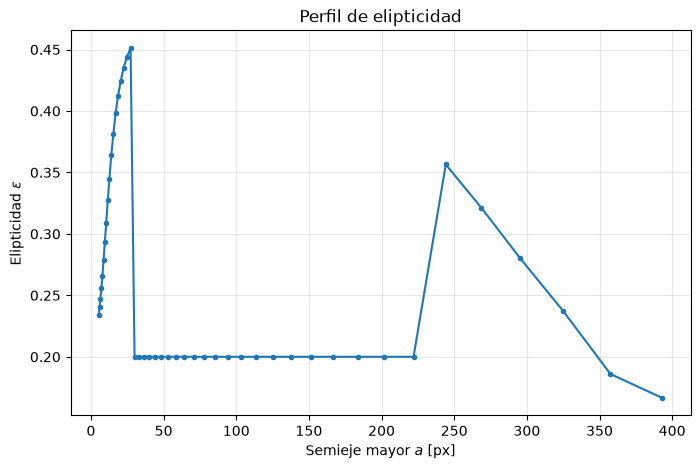

In [192]:
plt.figure(figsize=(8, 5))

plt.plot(
    sma,
    eps,
    ".-"
)

plt.xlabel(r"Semieje mayor $a$ [px]")
plt.ylabel(r"Elipticidad $\epsilon$")
plt.title("Perfil de elipticidad")

plt.grid(alpha=0.3)
plt.show()

In [211]:
def seleccionar_isofotas_confiables(
    isolist,
    sigma_sky_suave,
    sma0=30,
    snr_min=5
):

    sma = np.asarray(isolist.sma)
    eps = np.asarray(isolist.eps)
    pa = np.asarray(isolist.pa)
    intens = np.asarray(isolist.intens)
    stop_code = np.asarray(isolist.stop_code)
    valid = np.asarray(isolist.valid, dtype=bool)

    # ---------------------------------------------
    # Condiciones básicas de calidad
    # ---------------------------------------------
    buena = (
        np.isfinite(sma) &
        np.isfinite(eps) &
        np.isfinite(pa) &
        np.isfinite(intens) &

        valid &

        # Solo convergencia normal
        (stop_code == 0) &

        # Señal suficientemente alta
        (intens > snr_min * sigma_sky_suave) &

        (eps >= 0) &
        (eps < 1)
    )

    # ---------------------------------------------
    # Encontrar el primer fallo hacia radios mayores
    # que sma0
    # ---------------------------------------------
    indices_out = np.where(
        sma >= sma0
    )[0]

    limite_externo = np.inf

    for idx in indices_out:

        if not buena[idx]:

            # El límite es la última isofota anterior
            anteriores = np.where(
                (sma < sma[idx]) &
                buena
            )[0]

            if len(anteriores) > 0:
                limite_externo = sma[
                    anteriores[-1]
                ]

            break

    # Si nunca falla, utilizamos todas las buenas
    if not np.isfinite(limite_externo):

        if np.any(buena):
            limite_externo = np.max(
                sma[buena]
            )
        else:
            raise ValueError(
                "No se encontraron isofotas confiables."
            )

    mascara_final = (
        buena &
        (sma <= limite_externo)
    )

    return {
        "sma": sma,
        "eps": eps,
        "pa": pa,
        "intens": intens,
        "stop_code": stop_code,
        "valid": valid,
        "buena": mascara_final,
        "limite_externo": limite_externo
    }

### Perfil radial de elipticidad

El ajuste de isofotas proporciona una estimación de

$$
\epsilon(R)=1-\frac{b(R)}{a(R)}
$$

a diferentes radios.

La región más interna puede estar afectada por la PSF y por pequeñas
estructuras nucleares, mientras que las isofotas más externas pueden presentar
mayor incertidumbre debido al bajo brillo superficial.

Por este motivo, para la clasificación no se adopta directamente la primera ni
la última isofota. Se busca una región intermedia-externa donde la elipticidad
sea aproximadamente estable y se utiliza la mediana de sus valores.

Esta estrategia reduce la sensibilidad de la clasificación a una única
medición y permite comprobar visualmente la estabilidad geométrica de la
galaxia.

In [232]:
def elipticidad_representativa(
    datos_isofotas,
    n_ventana=5,
    dispersion_max=0.04,
    frac_min=0.30,
    frac_max=0.70
):

    sma = datos_isofotas["sma"]
    eps = datos_isofotas["eps"]
    buena = datos_isofotas["buena"]

    # --------------------------------------------
    # Solo isofotas confiables
    # --------------------------------------------
    sma_good = sma[buena]
    eps_good = eps[buena]

    if len(eps_good) < n_ventana:
        raise ValueError(
            "No hay suficientes isofotas confiables."
        )

    # Orden radial
    orden = np.argsort(sma_good)

    sma_good = sma_good[orden]
    eps_good = eps_good[orden]

    # --------------------------------------------
    # Definir región radial intermedia
    # usando únicamente el rango confiable
    # --------------------------------------------
    r_min = np.min(sma_good)
    r_max = np.max(sma_good)

    r1 = r_min + frac_min * (r_max - r_min)
    r2 = r_min + frac_max * (r_max - r_min)

    mascara_intermedia = (
        (sma_good >= r1) &
        (sma_good <= r2)
    )

    sma_mid = sma_good[mascara_intermedia]
    eps_mid = eps_good[mascara_intermedia]

    if len(eps_mid) < n_ventana:
        raise ValueError(
            "No hay suficientes isofotas en "
            "la región radial intermedia."
        )

    # --------------------------------------------
    # Buscar ventanas estables
    # --------------------------------------------
    candidatas = []

    for i in range(
        len(eps_mid) - n_ventana + 1
    ):

        e = eps_mid[i:i+n_ventana]
        a = sma_mid[i:i+n_ventana]

        mediana = np.median(e)

        mad = np.median(
            np.abs(e - mediana)
        )

        sigma_robusta = 1.4826 * mad

        if sigma_robusta <= dispersion_max:

            candidatas.append({
                "sma": a,
                "eps": e,
                "eps_med": mediana,
                "sigma": sigma_robusta,
                "radio_med": np.median(a)
            })

    if len(candidatas) == 0:
        raise ValueError(
            "No se encontró una región estable."
        )

    # --------------------------------------------
    # Elegir la ventana estable más cercana
    # al centro de la región radial útil
    # --------------------------------------------
    r_objetivo = 0.5 * (r1 + r2)

    mejor = min(
        candidatas,
        key=lambda x:
        abs(x["radio_med"] - r_objetivo)
    )

    return (
        mejor["eps_med"],
        mejor["sigma"],
        mejor["sma"],
        mejor["eps"]
    )

In [213]:
def clasificar_eliptica(epsilon):

    n = int(
        np.floor(
            10 * epsilon + 0.5
        )
    )

    # Clasificación observada de Hubble:
    # E0 ... E7
    n = np.clip(
        n,
        0,
        7
    )

    return f"E{n}"

In [223]:
def clasificador_hubble_eliptica(
    ruta_fits,
    borde=100,
    sigma_smooth=3,
    radio_momentos=50,
    sma0=30,
    minsma=5,
    maxsma=None,
    snr_min=5,
    n_externas=7
):

    # ==================================================
    # 1. Preparar imagen
    # ==================================================

    (
        imagen,
        imagen_sky,
        imagen_suave,
        sky,
        sigma_sky,
        sigma_sky_suave
    ) = preparar_imagen_eliptica(
        ruta_fits,
        borde=borde,
        sigma_smooth=sigma_smooth
    )

    # ==================================================
    # 2. Centro fotométrico
    # ==================================================

    xc, yc = estimar_centro(
        imagen_suave
    )

    # ==================================================
    # 3. Geometría inicial automática
    # ==================================================

    eps0, pa0 = estimar_geometria_inicial(
        imagen_suave,
        xc,
        yc,
        sigma_sky_suave,
        radio=radio_momentos
    )

    # ==================================================
    # 4. Ajuste de isofotas
    # ==================================================

    isolist = ajustar_isofotas_eliptica(
        imagen_suave,
        xc,
        yc,
        eps0,
        pa0,
        sma0=sma0,
        minsma=minsma,
        maxsma=maxsma
    )

    # ==================================================
    # 5. Selección de isofotas confiables
    # ==================================================

    datos = seleccionar_isofotas_confiables(
        isolist,
        sigma_sky_suave,
        sma0=sma0,
        snr_min=snr_min
    )

    # ==================================================
    # 6. Elipticidad representativa
    # ==================================================

    (
        eps_med,
        eps_sigma,
        sma_sel,
        eps_sel
    ) = elipticidad_representativa(
        datos,
        n_ventana=5,
        dispersion_max=0.04
    )

    # ==================================================
    # 7. Clasificación
    # ==================================================

    tipo = clasificar_eliptica(
        eps_med
    )

    # ==================================================
    # 8. Resultado
    # ==================================================

    resultado = {

        "tipo": tipo,

        "epsilon": eps_med,
        "epsilon_sigma": eps_sigma,

        "epsilon_inicial": eps0,
        "pa_inicial_deg": np.degrees(pa0),

        "centro_x": xc,
        "centro_y": yc,

        "sky": sky,
        "sigma_sky": sigma_sky,

        "sigma_sky_suave": sigma_sky_suave,

        "sma_sel": sma_sel,
        "eps_sel": eps_sel,

        "isolist": isolist,
        "datos_isofotas": datos,

        "imagen": imagen,
        "imagen_sky": imagen_sky,
        "imagen_suave": imagen_suave
    }

    return resultado

In [236]:
resultado_3377 = clasificador_hubble_eliptica(
    "datos/NGC 3377_SDSS9_g.fits",
    radio_momentos=50,
    sma0=30,
    snr_min=5,
    n_externas=7
)
print("Resultados para NGC 3377:")
print(
    f"Centro: "
    f"({resultado_3377['centro_x']:.2f}, "
    f"{resultado_3377['centro_y']:.2f}) px"
)

print(
    f"epsilon inicial = "
    f"{resultado_3377['epsilon_inicial']:.3f}"
)

print(
    f"PA inicial = "
    f"{resultado_3377['pa_inicial_deg']:.2f} deg"
)

print(
    f"epsilon representativa = "
    f"{resultado_3377['epsilon']:.3f} "
    f"± {resultado_3377['epsilon_sigma']:.3f}"
)

print(
    f"Clasificación Hubble = "
    f"{resultado_3377['tipo']}"
)

Resultados para NGC 3377:
Centro: (539.85, 544.78) px
epsilon inicial = 0.217
PA inicial = 130.58 deg
epsilon representativa = 0.405 ± 0.014
Clasificación Hubble = E4


In [237]:
resultado_M87 = clasificador_hubble_eliptica(
    "datos/M87_SDSS9_g.fits",
    radio_momentos=50,
    sma0=30,
    snr_min=5,
    n_externas=7
)

print("Resultados para M87:")
print(
    f"Centro: "
    f"({resultado_M87['centro_x']:.2f}, "
    f"{resultado_M87['centro_y']:.2f}) px"
)

print(
    f"epsilon inicial = "
    f"{resultado_M87['epsilon_inicial']:.3f}"
)

print(
    f"PA inicial = "
    f"{resultado_M87['pa_inicial_deg']:.2f} deg"
)

print(
    f"epsilon representativa = "
    f"{resultado_M87['epsilon']:.3f} "
    f"± {resultado_M87['epsilon_sigma']:.3f}"
)

print(
    f"Clasificación Hubble = "
    f"{resultado_M87['tipo']}"
)

Resultados para M87:
Centro: (899.30, 899.55) px
epsilon inicial = 0.015
PA inicial = 37.61 deg
epsilon representativa = 0.137 ± 0.019
Clasificación Hubble = E1


### Resultados de la clasificación de galaxias elípticas

El mismo procedimiento fotométrico fue aplicado a las dos galaxias, utilizando
isofotas con buena señal, ajustes convergentes y una región radial intermedia
donde la elipticidad presenta un comportamiento estable.

Para NGC 3377 se obtuvo $\epsilon_{\rm rep}=0.405\pm0.014$ por lo que $10\epsilon\simeq4.05$ y se adopta la clasificación

$$
\boxed{\mathrm{NGC\ 3377:\ E4}}.
$$

Para M87 se obtuvo $\epsilon_{\rm rep}=0.137\pm0.019$ de manera que $10\epsilon\simeq1.37$ lo que conduce a

$$
\boxed{\mathrm{M87:\ E1}}.
$$

La clasificación se obtiene directamente a partir de la definición geométrica
del sistema de Hubble para galaxias elípticas,

$$
\epsilon=1-\frac{b}{a},
\qquad
E_n,\quad n\simeq10\epsilon.
$$

La robustez del procedimiento proviene de que no se utiliza una única isofota.
En su lugar, se consideran múltiples isofotas con buena relación señal-ruido,
se descartan ajustes problemáticos y se selecciona una región radial donde
$\epsilon(R)$ permanece aproximadamente estable.

Además, se utilizó exactamente el mismo procedimiento para ambas galaxias,
sin introducir manualmente la elipticidad esperada de cada objeto.

Las pequeñas diferencias que puedan existir respecto a clasificaciones
catalogadas son esperables, ya que la elipticidad observada puede variar con
el radio y la clasificación Hubble representa una caracterización de la
morfología proyectada de la galaxia.

In [313]:
resultado_M32 = clasificador_hubble_eliptica(
    "datos/M32_PanSTARRS_DR1_g.fits",
    radio_momentos=50,
    sma0=30,
    snr_min=5,
    n_externas=7
)

print("Resultados para M32:")
print(
    f"Centro: "
    f"({resultado_M32['centro_x']:.2f}, "
    f"{resultado_M32['centro_y']:.2f}) px"
)

print(
    f"epsilon inicial = "
    f"{resultado_M32['epsilon_inicial']:.3f}"
)

print(
    f"PA inicial = "
    f"{resultado_M32['pa_inicial_deg']:.2f}°"
)

print(
    f"epsilon representativa = "
    f"{resultado_M32['epsilon']:.3f} "
    f"± {resultado_M32['epsilon_sigma']:.3f}"
)

print(
    f"Clasificación Hubble = "
    f"{resultado_M32['tipo']}"
)

Resultados para M32:
Centro: (598.00, 600.24) px
epsilon inicial = 0.098
PA inicial = 70.72°
epsilon representativa = 0.161 ± 0.008
Clasificación Hubble = E2


## Clasificador morfológico para galaxias de disco

La clasificación de Hubble para galaxias de disco requiere distinguir primero
entre espirales normales y espirales barradas,

$$
S \qquad {\rm y} \qquad SB,
$$

y posteriormente determinar el subtipo morfológico $a$, $b$ o $c$.

En este análisis se utilizarán tres propiedades observacionales:

1. la geometría de las isofotas, para estimar la orientación e inclinación
   aparente del disco y buscar evidencia de una barra;

2. el *pitch angle* de los brazos espirales, que mide qué tan abiertos o
   enrollados son los brazos;

3. la importancia de la componente central respecto al disco exponencial,
   utilizada como criterio complementario.

Como valores de referencia se consideran aproximadamente

$$
\begin{array}{c|c|c}
\text{Tipo} & L_{\rm bulbo}/L_{\rm disco} & \text{Pitch angle}\\
\hline
Sa & \sim0.3 & \sim6^\circ\\
Sb & >0.1 & \sim12^\circ\\
Sc & \sim0.05 & \sim18^\circ
\end{array}
$$

El algoritmo utilizará el *pitch angle* como indicador principal del subtipo
y la estructura central como una comprobación adicional.

La clasificación obtenida debe interpretarse como una estimación morfológica,
ya que las propiedades de una galaxia real pueden situarla entre dos categorías
del esquema de Hubble.

In [262]:
from scipy.ndimage import label, binary_opening, binary_closing

In [263]:
def estimar_geometria_disco(
    imagen_sky,
    sigma_sky,
    xc,
    yc,
    snr_min=3,
    r_max=None
):

    imagen = np.asarray(
        imagen_sky,
        dtype=float
    ).copy()

    imagen[~np.isfinite(imagen)] = 0

    ny, nx = imagen.shape

    y, x = np.indices(
        imagen.shape
    )

    # --------------------------------------------------
    # 1. Distancia al centro aproximado
    # --------------------------------------------------

    r = np.sqrt(
        (x - xc)**2 +
        (y - yc)**2
    )

    if r_max is None:

        # Por defecto solo consideramos la región
        # central de la imagen donde debe estar la galaxia
        r_max = 0.25 * min(nx, ny)

    # --------------------------------------------------
    # 2. Umbral de detección + restricción radial
    # --------------------------------------------------

    mascara = (
        (imagen > snr_min * sigma_sky) &
        (r <= r_max)
    )

    # --------------------------------------------------
    # 3. Limpiar pequeños puentes y huecos
    # --------------------------------------------------

    estructura = np.ones(
        (3, 3),
        dtype=bool
    )

    mascara = binary_opening(
        mascara,
        structure=estructura,
        iterations=1
    )

    mascara = binary_closing(
        mascara,
        structure=estructura,
        iterations=2
    )

    # --------------------------------------------------
    # 4. Componentes conectadas
    # --------------------------------------------------

    etiquetas, numero = label(
        mascara
    )

    if numero == 0:
        raise ValueError(
            "No se detectó ninguna región significativa."
        )

    xi = int(round(xc))
    yi = int(round(yc))

    etiqueta_central = etiquetas[
        yi,
        xi
    ]

    # Si el píxel central no quedó dentro de la máscara,
    # elegir la componente cuyo centro esté más cerca.
    if etiqueta_central == 0:

        mejor = None
        distancia_min = np.inf

        for k in range(1, numero + 1):

            yy, xx = np.where(
                etiquetas == k
            )

            if len(xx) == 0:
                continue

            xmed = np.mean(xx)
            ymed = np.mean(yy)

            distancia = np.hypot(
                xmed - xc,
                ymed - yc
            )

            if distancia < distancia_min:

                distancia_min = distancia
                mejor = k

        etiqueta_central = mejor

    mascara_galaxia = (
        etiquetas == etiqueta_central
    )

    # --------------------------------------------------
    # 5. Centro geométrico de la máscara
    # --------------------------------------------------

    yy, xx = np.where(
        mascara_galaxia
    )

    if len(xx) < 10:
        raise ValueError(
            "La región detectada es demasiado pequeña."
        )

    xc_ref = np.mean(xx)
    yc_ref = np.mean(yy)

    dx = xx - xc_ref
    dy = yy - yc_ref

    # --------------------------------------------------
    # 6. Momentos geométricos de la máscara
    # --------------------------------------------------

    Mxx = np.mean(dx**2)
    Myy = np.mean(dy**2)
    Mxy = np.mean(dx * dy)

    matriz = np.array([
        [Mxx, Mxy],
        [Mxy, Myy]
    ])

    valores, vectores = np.linalg.eigh(
        matriz
    )

    orden = np.argsort(
        valores
    )[::-1]

    valores = valores[orden]
    vectores = vectores[:, orden]

    lambda_a = valores[0]
    lambda_b = valores[1]

    # --------------------------------------------------
    # 7. Relación de ejes
    # --------------------------------------------------

    q = np.sqrt(
        lambda_b / lambda_a
    )

    q = np.clip(
        q,
        0,
        1
    )

    epsilon = 1 - q

    # --------------------------------------------------
    # 8. PA
    # --------------------------------------------------

    vx = vectores[0, 0]
    vy = vectores[1, 0]

    pa_rad = np.arctan2(
        vy,
        vx
    )

    pa_rad = pa_rad % np.pi

    pa_deg = np.degrees(
        pa_rad
    )

    # --------------------------------------------------
    # 9. Inclinación aproximada
    # --------------------------------------------------

    inclinacion = np.degrees(
        np.arccos(q)
    )

    return {
        "xc": xc_ref,
        "yc": yc_ref,
        "epsilon": epsilon,
        "q": q,
        "pa_rad": pa_rad,
        "pa_deg": pa_deg,
        "inclinacion_deg": inclinacion,
        "mascara": mascara_galaxia,
        "r_max": r_max
    }

In [253]:
def ajustar_isofotas_disco(
    imagen_suave,
    xc,
    yc,
    eps0,
    pa0,
    sma0=40,
    minsma=10,
    maxsma=None
):

    ny, nx = imagen_suave.shape

    if maxsma is None:
        maxsma = 0.40 * min(nx, ny)

    geometria = EllipseGeometry(
        x0=xc,
        y0=yc,
        sma=sma0,
        eps=eps0,
        pa=pa0
    )

    ellipse = Ellipse(
        imagen_suave,
        geometry=geometria
    )

    isolist = ellipse.fit_image(
        sma0=sma0,
        minsma=minsma,
        maxsma=maxsma,
        step=0.1,

        sclip=3,
        n_clip=3,

        # Para discos permitimos un pequeño refinamiento del centro
        fix_center=False,

        fix_pa=False,
        fix_eps=False
    )

    return isolist

In [239]:
def extraer_geometria_isofotas(isolist):

    datos = {
        "sma": np.asarray(isolist.sma),
        "eps": np.asarray(isolist.eps),
        "pa": np.asarray(isolist.pa),
        "intens": np.asarray(isolist.intens),
        "stop_code": np.asarray(isolist.stop_code),
        "valid": np.asarray(isolist.valid, dtype=bool)
    }

    return datos

In [240]:
def graficar_geometria_disco(datos):

    sma = datos["sma"]
    eps = datos["eps"]

    # Convertimos PA a grados solo para visualizar
    pa_deg = np.degrees(
        np.unwrap(datos["pa"])
    )

    # -------------------------------
    # Elipticidad
    # -------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        sma,
        eps,
        ".-"
    )

    plt.xlabel(r"Semieje mayor $a$ [px]")
    plt.ylabel(r"Elipticidad $\epsilon$")
    plt.title("Perfil de elipticidad")

    plt.grid(alpha=0.3)
    plt.show()

    # -------------------------------
    # Ángulo de posición
    # -------------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        sma,
        pa_deg,
        ".-"
    )

    plt.xlabel(r"Semieje mayor $a$ [px]")
    plt.ylabel("PA [deg]")
    plt.title("Perfil del ángulo de posición")

    plt.grid(alpha=0.3)
    plt.show()

In [241]:
def geometria_externa_disco(
    isolist,
    sigma_sky_suave,
    snr_min=5,
    frac_min=0.60,
    frac_max=0.85
):

    sma = np.asarray(isolist.sma)
    eps = np.asarray(isolist.eps)
    pa = np.asarray(isolist.pa)
    intens = np.asarray(isolist.intens)

    stop_code = np.asarray(isolist.stop_code)
    valid = np.asarray(isolist.valid, dtype=bool)

    # -------------------------------------
    # Isofotas utilizables
    # -------------------------------------

    buena = (
        np.isfinite(sma) &
        np.isfinite(eps) &
        np.isfinite(pa) &
        np.isfinite(intens) &

        valid &
        (stop_code == 0) &

        (intens > snr_min * sigma_sky_suave) &

        (eps >= 0) &
        (eps < 1)
    )

    sma_good = sma[buena]
    eps_good = eps[buena]
    pa_good = pa[buena]

    if len(sma_good) < 5:
        raise ValueError(
            "No hay suficientes isofotas confiables "
            "para determinar la geometría del disco."
        )

    # -------------------------------------
    # Zona externa del rango CONFIABLE
    # -------------------------------------

    rmin = np.min(sma_good)
    rmax = np.max(sma_good)

    r1 = rmin + frac_min * (rmax - rmin)
    r2 = rmin + frac_max * (rmax - rmin)

    region = (
        (sma_good >= r1) &
        (sma_good <= r2)
    )

    sma_sel = sma_good[region]
    eps_sel = eps_good[region]
    pa_sel = pa_good[region]

    if len(eps_sel) < 3:
        raise ValueError(
            "Muy pocas isofotas en la región externa."
        )

    # -------------------------------------
    # Valores representativos
    # -------------------------------------

    eps_disco = np.median(eps_sel)

    # Mediana del PA desenrollado
    pa_unwrap = np.unwrap(pa_sel)

    pa_disco = np.median(
        pa_unwrap
    )

    q = 1 - eps_disco

    q = np.clip(
        q,
        0,
        1
    )

    inclinacion = np.degrees(
        np.arccos(q)
    )

    return {
        "epsilon": eps_disco,
        "q": q,
        "pa_rad": pa_disco,
        "pa_deg": np.degrees(pa_disco),
        "inclinacion_deg": inclinacion,
        "sma_sel": sma_sel,
        "eps_sel": eps_sel,
        "pa_sel": pa_sel
    }

In [245]:
imagen, imagen_sky, imagen_suave, sky, sigma_sky, sigma_sky_suave = preparar_imagen_eliptica(
    "datos/NGC2403_SDSS_g.fits"
)

In [246]:
xc, yc = estimar_centro(
    imagen_suave
)

In [264]:
geometria_disco = estimar_geometria_disco(
    imagen_sky,
    sigma_sky,
    xc,
    yc,
    snr_min=3,
    r_max=900
)

In [265]:
print(
    f"Centro refinado = "
    f"({geometria_disco['xc']:.2f}, "
    f"{geometria_disco['yc']:.2f}) px"
)

print(
    f"epsilon = "
    f"{geometria_disco['epsilon']:.3f}"
)

print(
    f"b/a = "
    f"{geometria_disco['q']:.3f}"
)

print(
    f"PA = "
    f"{geometria_disco['pa_deg']:.2f} deg"
)

print(
    f"Inclinación = "
    f"{geometria_disco['inclinacion_deg']:.2f} deg"
)

Centro refinado = (2075.20, 2139.90) px
epsilon = 0.435
b/a = 0.565
PA = 49.60 deg
Inclinación = 55.57 deg


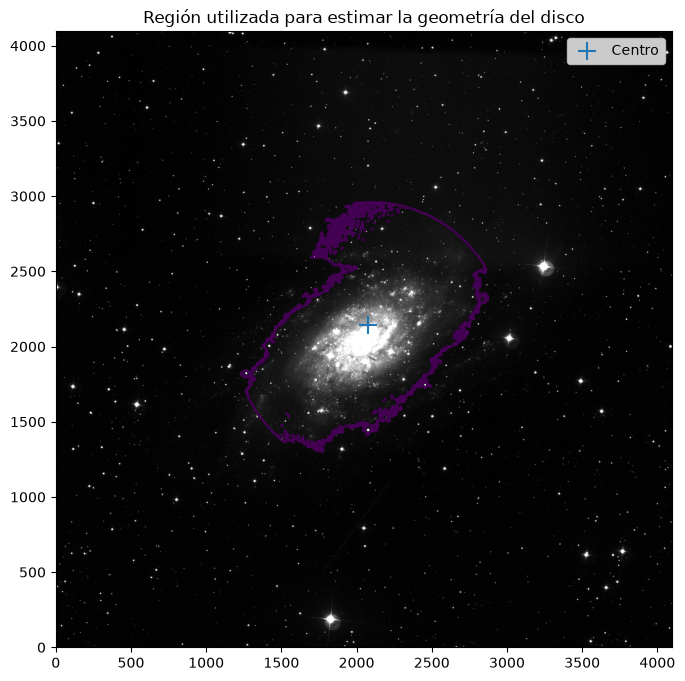

In [266]:
plt.figure(figsize=(8, 8))

vmin = np.nanpercentile(
    imagen_sky,
    10
)

vmax = np.nanpercentile(
    imagen_sky,
    99.5
)

plt.imshow(
    imagen_sky,
    origin="lower",
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

plt.contour(
    geometria_disco["mascara"],
    levels=[0.5],
    linewidths=1.5
)

plt.scatter(
    geometria_disco["xc"],
    geometria_disco["yc"],
    marker="+",
    s=150,
    label="Centro"
)

plt.title(
    "Región utilizada para estimar la geometría del disco"
)

plt.legend()
plt.show()

## 3. Distribución espacial de los cúmulos globulares de la Vía Láctea

El catálogo `GCs_MW.csv` proporciona para cada cúmulo globular, entre otras
cantidades, su longitud galáctica $l$, latitud galáctica $b$, distancia
heliocéntrica $d$ y metalicidad $[\mathrm{Fe/H}]$.

El objetivo inicial es reconstruir la distribución tridimensional de los
cúmulos tomando al Sol como origen.

Para ello se utilizarán las coordenadas cartesianas heliocéntricas

$$
x=d\cos b\cos l,
$$

$$
y=d\cos b\sin l,
$$

$$
z=d\sin b.
$$

En esta convención:

- el Sol se encuentra en $(0,0,0)$;
- el eje $x$ positivo apunta hacia $l=0^\circ$, aproximadamente hacia el
  centro galáctico;
- el eje $y$ positivo apunta hacia $l=90^\circ$;
- el eje $z$ positivo apunta hacia el polo norte galáctico.


In [281]:
ruta_gc = "datos/GCs_MW.csv"

filas = []

with open(ruta_gc, "r") as archivo:

    for linea in archivo:

        # Ignorar cabecera y líneas vacías
        if linea.startswith("#") or not linea.strip():
            continue

        def leer_numero(a, b):
            valor = linea[a:b].strip()

            if valor == "":
                return np.nan

            return float(valor)

        filas.append({
            "ID": linea[0:9].strip(),
            "RAJ2000": linea[10:20].strip(),
            "DEJ2000": linea[21:30].strip(),
            "GLON": leer_numero(31, 37),
            "GLAT": leer_numero(38, 44),
            "Rsun": leer_numero(45, 50),
            "Rgc": leer_numero(51, 56),
            "Vt": leer_numero(57, 62),
            "FeH": leer_numero(63, 68)
        })

gc = pd.DataFrame(filas)

print("Número de cúmulos:", len(gc))
display(gc.head())

Número de cúmulos: 147


,ID,RAJ2000,DEJ2000,GLON,GLAT,Rsun,Rgc,Vt,FeH
0,NGC 104,00 24 05.2,-72 04 51,305.90,-44.89,4.3,7.3,3.95,-0.76
1,NGC 288,00 52 47.5,-26 35 24,152.28,-89.38,8.1,11.4,8.09,-1.24
2,NGC 362,01 03 14.3,-70 50 54,301.53,-46.25,8.3,9.2,6.40,-1.16
3,NGC 1261,03 12 15.3,-55 13 01,270.54,-52.13,16.0,17.9,8.29,-1.35
4,Pal 1,03 33 23.0,+79 34 50,130.07,19.03,9.7,15.9,13.52,-0.80


In [282]:
gc.isna().sum()

ID         0
RAJ2000    0
DEJ2000    0
GLON       0
GLAT       0
Rsun       2
Rgc        2
Vt         1
FeH        8
dtype: int64

### Reconstrucción tridimensional en un sistema heliocéntrico

Se seleccionan únicamente los cúmulos que poseen una distancia heliocéntrica válida.

Las coordenadas angulares galácticas se convierten de grados a radianes y posteriormente se calculan las coordenadas cartesianas $(x,y,z)$.

Si la distribución de cúmulos estuviera centrada en el Sol, se esperaría que su centro espacial se encontrara aproximadamente en $(0,0,0)$.

En cambio, un desplazamiento sistemático de la distribución permitirá localizar la dirección del centro galáctico.

In [283]:
gc_xyz = gc.dropna(
    subset=["GLON", "GLAT", "Rsun"]
).copy()

l = np.radians(gc_xyz["GLON"])
b = np.radians(gc_xyz["GLAT"])
d = gc_xyz["Rsun"]

gc_xyz["x"] = d * np.cos(b) * np.cos(l)
gc_xyz["y"] = d * np.cos(b) * np.sin(l)
gc_xyz["z"] = d * np.sin(b)

print(
    f"Cúmulos utilizados: {len(gc_xyz)}"
)

display(
    gc_xyz[
        ["ID", "GLON", "GLAT", "Rsun", "x", "y", "z"]
    ].head()
)

Cúmulos utilizados: 145


,ID,GLON,GLAT,Rsun,x,y,z
0,NGC 104,305.90,-44.89,4.3,1.786319,-2.467704,-3.034716
1,NGC 288,152.28,-89.38,8.1,-0.077589,0.040770,-8.099526
2,NGC 362,301.53,-46.25,8.3,3.001473,-4.892207,-5.995621
3,NGC 1261,270.54,-52.13,16.0,0.092568,-9.821515,-12.630490
4,Pal 1,130.07,19.03,9.7,-5.902860,7.017326,3.162813


In [288]:
import plotly.graph_objects as go

In [295]:
fig = go.Figure()

# ---------------------------------------------
# Cúmulos globulares
# ---------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=gc_xyz["x"],
        y=gc_xyz["y"],
        z=gc_xyz["z"],

        mode="markers",

        marker=dict(
            size=4,
            opacity=0.75
        ),

        text=gc_xyz["ID"],

        hovertemplate=(
            "<b>%{text}</b><br>"
            "x = %{x:.2f} kpc<br>"
            "y = %{y:.2f} kpc<br>"
            "z = %{z:.2f} kpc"
            "<extra></extra>"
        ),

        name="Cúmulos globulares"
    )
)

# ---------------------------------------------
# Sol
# ---------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],

        mode="markers+text",

        marker=dict(
            size=6,
            symbol="circle"
        ),

        text=["Sol"],
        textposition="top center",

        name="Sol"
    )
)

# ---------------------------------------------
# Diseño
# ---------------------------------------------
fig.update_layout(

    title="Distribución heliocéntrica de cúmulos globulares",

    scene=dict(

        xaxis_title="x [kpc]",
        yaxis_title="y [kpc]",
        zaxis_title="z [kpc]",

        aspectmode="data"
    ),

    width=900,
    height=750
)

fig.show()

In [297]:
def mediana_geometrica(puntos, tol=1e-7, max_iter=1000):

    puntos = np.asarray(
        puntos,
        dtype=float
    )

    # Semilla inicial
    centro = np.median(
        puntos,
        axis=0
    )

    for _ in range(max_iter):

        distancias = np.linalg.norm(
            puntos - centro,
            axis=1
        )

        # Evitar división por cero
        distancias = np.maximum(
            distancias,
            1e-12
        )

        pesos = 1 / distancias

        nuevo_centro = np.sum(
            puntos * pesos[:, None],
            axis=0
        ) / np.sum(pesos)

        if np.linalg.norm(
            nuevo_centro - centro
        ) < tol:
            break

        centro = nuevo_centro

    return centro

In [298]:
posiciones = gc_xyz[
    ["x", "y", "z"]
].to_numpy()

centro_gc = mediana_geometrica(
    posiciones
)

xc_gc, yc_gc, zc_gc = centro_gc

R0_estimado = np.linalg.norm(
    centro_gc
)

print(
    f"Centro estimado = "
    f"({xc_gc:.2f}, "
    f"{yc_gc:.2f}, "
    f"{zc_gc:.2f}) kpc"
)

print(
    f"Distancia Sol-centro = "
    f"{R0_estimado:.2f} kpc"
)

Centro estimado = (7.37, -0.04, 0.14) kpc
Distancia Sol-centro = 7.37 kpc


### Centro de la distribución de cúmulos globulares

La distribución espacial de los cúmulos no se encuentra centrada en la
posición del Sol.

Utilizando una mediana geométrica tridimensional se obtiene aproximadamente

$$
(x_c,y_c,z_c)
\simeq
(7.37,-0.04,0.14)\ {\rm kpc}.
$$

La componente dominante del desplazamiento ocurre sobre el eje $x$, cuya
dirección positiva fue definida hacia $l=0^\circ$, es decir, hacia la región
del centro galáctico.

La distancia entre el Sol y el centro estimado de la distribución es

$$
R_0=
\sqrt{x_c^2+y_c^2+z_c^2},
$$

de donde

$$
\boxed{
R_0\simeq7.37\ {\rm kpc}.
}
$$

El hecho de que $y_c$ y $z_c$ sean pequeños en comparación con $x_c$ muestra
además que la concentración se encuentra aproximadamente en la dirección
esperada del centro galáctico.

La estimación es cercana al valor de aproximadamente $8$ kpc aceptado para la
distancia entre el Sol y el centro de la Vía Láctea. Las diferencias pueden
deberse a la distribución no perfectamente simétrica de los cúmulos,
la presencia de objetos muy alejados y las incertidumbres observacionales.

In [300]:
fig = go.Figure()

# ---------------------------------------------
# Cúmulos
# ---------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=gc_xyz["x"],
        y=gc_xyz["y"],
        z=gc_xyz["z"],

        mode="markers",

        marker=dict(
            size=4,
            opacity=0.65
        ),

        text=gc_xyz["ID"],

        hovertemplate=(
            "<b>%{text}</b><br>"
            "x = %{x:.2f} kpc<br>"
            "y = %{y:.2f} kpc<br>"
            "z = %{z:.2f} kpc"
            "<extra></extra>"
        ),

        name="Cúmulos globulares"
    )
)

# ---------------------------------------------
# Sol
# ---------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],

        mode="markers+text",

        marker=dict(
            size=7,
            symbol="circle"
        ),

        text=["Sol"],
        textposition="top center",

        name="Sol"
    )
)

# ---------------------------------------------
# Centro de la distribución
# ---------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=[xc_gc],
        y=[yc_gc],
        z=[zc_gc],

        mode="markers+text",

        marker=dict(
            size=8,
            symbol="square"
        ),

        text=["Centro estimado"],
        textposition="top center",

        name="Centro estimado"
    )
)

fig.update_layout(

    title=(
        "Distribución de cúmulos globulares y "
        "centro espacial estimado"
    ),

    scene=dict(

        xaxis_title="x [kpc]",
        yaxis_title="y [kpc]",
        zaxis_title="z [kpc]",

        aspectmode="data"
    ),

    width=900,
    height=750
)

fig.show()

### Distribución espacial de los cúmulos según su metalicidad

Para estudiar si la distribución espacial de los cúmulos globulares depende de
su composición química, se utiliza la metalicidad

$$
[\mathrm{Fe/H}],
$$

disponible en el catálogo.

Primero se trasladan las coordenadas heliocéntricas al sistema cuyo origen es
el centro de la distribución de cúmulos obtenido anteriormente:

$$
X=x-x_c,
$$

$$
Y=y-y_c,
$$

$$
Z=z-z_c.
$$

De esta manera, $(X,Y,Z)=(0,0,0)$ representa aproximadamente el centro
galáctico inferido a partir de los propios datos.

Siguiendo la separación utilizada habitualmente para los cúmulos globulares,
se consideran dos poblaciones:

$$
[\mathrm{Fe/H}]\leq -0.8
\qquad
\text{(pobres en metales)},
$$

y

$$
[\mathrm{Fe/H}]>-0.8
\qquad
\text{(ricos en metales)}.
$$

El objetivo es comparar la extensión radial y vertical de ambas poblaciones.

In [301]:
gc_met = gc_xyz.dropna(
    subset=["FeH"]
).copy()

# Centro encontrado anteriormente
xc_gc, yc_gc, zc_gc = centro_gc

gc_met["X"] = gc_met["x"] - xc_gc
gc_met["Y"] = gc_met["y"] - yc_gc
gc_met["Z"] = gc_met["z"] - zc_gc

# Distancia cilíndrica al eje galáctico
gc_met["R"] = np.sqrt(
    gc_met["X"]**2 +
    gc_met["Y"]**2
)

# Distancia tridimensional al centro
gc_met["r3D"] = np.sqrt(
    gc_met["X"]**2 +
    gc_met["Y"]**2 +
    gc_met["Z"]**2
)

print(
    "Cúmulos con metalicidad disponible:",
    len(gc_met)
)

Cúmulos con metalicidad disponible: 139


In [302]:
fig = go.Figure()

fig.add_trace(
    go.Scatter3d(
        x=gc_met["X"],
        y=gc_met["Y"],
        z=gc_met["Z"],

        mode="markers",

        marker=dict(
            size=5,
            color=gc_met["FeH"],
            colorscale="Viridis",
            colorbar=dict(
                title="[Fe/H]"
            ),
            opacity=0.8
        ),

        text=gc_met["ID"],

        customdata=np.column_stack([
            gc_met["FeH"],
            gc_met["Rsun"]
        ]),

        hovertemplate=(
            "<b>%{text}</b><br>"
            "X = %{x:.2f} kpc<br>"
            "Y = %{y:.2f} kpc<br>"
            "Z = %{z:.2f} kpc<br>"
            "[Fe/H] = %{customdata[0]:.2f}<br>"
            "<extra></extra>"
        ),

        name="Cúmulos"
    )
)

# Centro galáctico
fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],

        mode="markers+text",

        marker=dict(
            size=8,
            symbol="diamond"
        ),

        text=["Centro"],
        textposition="top center",

        name="Centro galáctico"
    )
)

fig.update_layout(
    title="Distribución espacial de los cúmulos según su metalicidad",

    scene=dict(
        xaxis_title="X [kpc]",
        yaxis_title="Y [kpc]",
        zaxis_title="Z [kpc]",
        aspectmode="data"
    ),

    width=900,
    height=750
)

fig.show()

In [303]:
limite_FeH = -0.8

pobres = gc_met[
    gc_met["FeH"] <= limite_FeH
].copy()

ricos = gc_met[
    gc_met["FeH"] > limite_FeH
].copy()

print(
    f"Pobres en metales: {len(pobres)}"
)

print(
    f"Ricos en metales: {len(ricos)}"
)

Pobres en metales: 107
Ricos en metales: 32


In [304]:
fig = go.Figure()

# -------------------------------------------------
# Pobres en metales
# -------------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=pobres["X"],
        y=pobres["Y"],
        z=pobres["Z"],

        mode="markers",

        marker=dict(
            size=5,
            opacity=0.65
        ),

        text=pobres["ID"],

        hovertemplate=(
            "<b>%{text}</b><br>"
            "X = %{x:.2f} kpc<br>"
            "Y = %{y:.2f} kpc<br>"
            "Z = %{z:.2f} kpc"
            "<extra></extra>"
        ),

        name=r"[Fe/H] ≤ -0.8"
    )
)

# -------------------------------------------------
# Ricos en metales
# -------------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=ricos["X"],
        y=ricos["Y"],
        z=ricos["Z"],

        mode="markers",

        marker=dict(
            size=7,
            opacity=0.9
        ),

        text=ricos["ID"],

        hovertemplate=(
            "<b>%{text}</b><br>"
            "X = %{x:.2f} kpc<br>"
            "Y = %{y:.2f} kpc<br>"
            "Z = %{z:.2f} kpc"
            "<extra></extra>"
        ),

        name=r"[Fe/H] > -0.8"
    )
)

# -------------------------------------------------
# Centro
# -------------------------------------------------
fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],

        mode="markers+text",

        marker=dict(
            size=9,
            symbol="diamond"
        ),

        text=["Centro"],
        textposition="top center",

        name="Centro galáctico"
    )
)

fig.update_layout(
    title="Distribución espacial según metalicidad",

    scene=dict(
        xaxis_title="X [kpc]",
        yaxis_title="Y [kpc]",
        zaxis_title="Z [kpc]",
        aspectmode="data"
    ),

    width=900,
    height=750
)

fig.show()

In [305]:
def resumen_poblacion(datos, nombre):

    print(nombre)
    print("-" * 40)

    print(
        f"N = {len(datos)}"
    )

    print(
        f"Mediana [Fe/H] = "
        f"{datos['FeH'].median():.2f}"
    )

    print(
        f"Mediana R = "
        f"{datos['R'].median():.2f} kpc"
    )

    print(
        f"Mediana |Z| = "
        f"{np.abs(datos['Z']).median():.2f} kpc"
    )

    print(
        f"Mediana r3D = "
        f"{datos['r3D'].median():.2f} kpc"
    )

    print()


resumen_poblacion(
    pobres,
    "Pobres en metales"
)

resumen_poblacion(
    ricos,
    "Ricos en metales"
)

Pobres en metales
----------------------------------------
N = 107
Mediana [Fe/H] = -1.54
Mediana R = 5.88 kpc
Mediana |Z| = 2.60 kpc
Mediana r3D = 7.12 kpc

Ricos en metales
----------------------------------------
N = 32
Mediana [Fe/H] = -0.53
Mediana R = 2.73 kpc
Mediana |Z| = 0.62 kpc
Mediana r3D = 2.80 kpc



### Análisis de la distribución según metalicidad

Los datos muestran que los cúmulos pobres en metales constituyen
una población espacialmente extendida, aproximadamente asociada al halo
galáctico, mientras que los cúmulos más ricos en metales se concentran
preferentemente hacia el plano y las regiones internas de la Galaxia.

Este comportamiento coincide con la interpretación de que la población
metal-pobre traza principalmente el halo estelar, mientras que la población
más rica en metales presenta una mayor asociación con las componentes
internas y aplanadas de la Vía Láctea.

### Comparación entre el disco galáctico y la distribución de cúmulos globulares

El archivo `disquito.dat` contiene una realización tridimensional del disco
galáctico mediante coordenadas $(x,y,z)$ centradas aproximadamente en el centro
de la Galaxia.

Como las posiciones de los cúmulos globulares fueron trasladadas previamente al
sistema galactocéntrico,

$$
X=x-x_c,\qquad
Y=y-y_c,\qquad
Z=z-z_c,
$$

ambos conjuntos de datos pueden representarse en el mismo sistema de referencia.

Esta comparación permite estudiar visualmente la diferencia entre la geometría
aplanada del disco y la distribución mucho más extendida de los cúmulos
globulares.

Además, se mantiene la separación según metalicidad:

$$
[\mathrm{Fe/H}]\leq-0.8
$$

para los cúmulos pobres en metales y

$$
[\mathrm{Fe/H}]>-0.8
$$

para los cúmulos más ricos en metales.

In [306]:
ruta_disco = "datos/disquito.dat"

disco = np.loadtxt(ruta_disco)

x_disco = disco[:, 0]
y_disco = disco[:, 1]
z_disco = disco[:, 2]

print("Número de puntos del disco:", len(disco))

print(
    f"Mediana |z| del disco = "
    f"{np.median(np.abs(z_disco)):.3f} kpc"
)

Número de puntos del disco: 20000
Mediana |z| del disco = 0.135 kpc


In [310]:
fig = go.Figure()

# ==========================================================
# DISCO GALÁCTICO
# ==========================================================

fig.add_trace(
    go.Scatter3d(
        x=x_disco,
        y=y_disco,
        z=z_disco,

        mode="markers",

        marker=dict(
            size=1.5,
            opacity=0.15,
            color="navy"
        ),

        name="Disco galáctico",

        hoverinfo="skip"
    )
)

# ==========================================================
# CÚMULOS POBRES EN METALES
# ==========================================================

fig.add_trace(
    go.Scatter3d(
        x=pobres["X"],
        y=pobres["Y"],
        z=pobres["Z"],

        mode="markers",

        marker=dict(
            size=4,
            opacity=0.65,
            color="blue"
        ),

        text=pobres["ID"],

        customdata=np.column_stack([
            pobres["FeH"],
            pobres["r3D"]
        ]),

        hovertemplate=(
            "<b>%{text}</b><br>"
            "X = %{x:.2f} kpc<br>"
            "Y = %{y:.2f} kpc<br>"
            "Z = %{z:.2f} kpc<br>"
            "[Fe/H] = %{customdata[0]:.2f}<br>"
            "r = %{customdata[1]:.2f} kpc"
            "<extra></extra>"
        ),

        name="[Fe/H] ≤ -0.8"
    )
)

# ==========================================================
# CÚMULOS RICOS EN METALES
# ==========================================================

fig.add_trace(
    go.Scatter3d(
        x=ricos["X"],
        y=ricos["Y"],
        z=ricos["Z"],

        mode="markers",

        marker=dict(
            size=5,
            opacity=0.9,
            color="red"
        ),

        text=ricos["ID"],

        customdata=np.column_stack([
            ricos["FeH"],
            ricos["r3D"]
        ]),

        hovertemplate=(
            "<b>%{text}</b><br>"
            "X = %{x:.2f} kpc<br>"
            "Y = %{y:.2f} kpc<br>"
            "Z = %{z:.2f} kpc<br>"
            "[Fe/H] = %{customdata[0]:.2f}<br>"
            "r = %{customdata[1]:.2f} kpc"
            "<extra></extra>"
        ),

        name="[Fe/H] > -0.8"
    )
)

# ==========================================================
# CENTRO GALÁCTICO
# ==========================================================

fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0],

        mode="markers+text",

        marker=dict(
            size=9,
            symbol="diamond"
        ),

        text=["Centro galáctico"],
        textposition="top center",

        name="Centro galáctico"
    )
)

# ==========================================================
# POSICIÓN DEL SOL EN EL SISTEMA GALACTOCÉNTRICO
# ==========================================================

x_sol = -xc_gc
y_sol = -yc_gc
z_sol = -zc_gc

fig.add_trace(
    go.Scatter3d(
        x=[x_sol],
        y=[y_sol],
        z=[z_sol],

        mode="markers+text",

        marker=dict(
            size=9,
            symbol="diamond"
        ),

        text=["Sol"],
        textposition="top center",

        name="Sol"
    )
)

# ==========================================================
# DISEÑO
# ==========================================================

fig.update_layout(

    title=(
        "Disco galáctico y distribución espacial "
        "de cúmulos globulares"
    ),

    scene=dict(

        xaxis_title="X [kpc]",
        yaxis_title="Y [kpc]",
        zaxis_title="Z [kpc]",

        aspectmode="data"
    ),

    width=950,
    height=800
)

fig.show()